In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/happysruti/438-ass-1/__results__.html
/kaggle/input/notebooks/happysruti/438-ass-1/__notebook__.ipynb
/kaggle/input/notebooks/happysruti/438-ass-1/__output__.json
/kaggle/input/notebooks/happysruti/438-ass-1/custom.css
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/comparison_sample_ids.json
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/metadata/preprocessing_config.json
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/metadata/class_info.json
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/metadata/training_class_distribution.csv
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/splits/all_splits.csv
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/encoded_masks/training/01301.png
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/encoded_masks/training/00929.png
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/encoded_masks/training/00704.png
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_out

In [2]:
# ============================================================
# CELL 1 — VERIFY AVAILABLE DOWNSTREAM INPUTS
# ============================================================

from pathlib import Path
import pandas as pd
import torch

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")

# ------------------------------------------------------------
# 1. Locate BYOL epoch-50 encoder
# ------------------------------------------------------------

byol_candidates = sorted(
    INPUT_ROOT.rglob("byol_encoder_epoch50.pth")
)

assert byol_candidates, (
    "BYOL epoch-50 encoder was not found. "
    "Add the completed BYOL pretraining notebook output."
)

BYOL_ENCODER_PATH = byol_candidates[0]

# ------------------------------------------------------------
# 2. Locate Data Prep CSV files
# ------------------------------------------------------------

train_candidates = sorted(
    INPUT_ROOT.rglob("train_ssl_images.csv")
)

shared_candidates = []

for train_path in train_candidates:
    candidate = train_path.parent

    if (
        (candidate / "val_finetune_images_masks.csv").exists()
        and
        (candidate / "test_monitor_eval_images_masks.csv").exists()
    ):
        shared_candidates.append(candidate)

assert shared_candidates, (
    "The required Data Prep CSV files were not found."
)

SHARED_ROOT = shared_candidates[0]

train_ssl_df = pd.read_csv(
    SHARED_ROOT / "train_ssl_images.csv"
)

val_finetune_df = pd.read_csv(
    SHARED_ROOT / "val_finetune_images_masks.csv"
)

test_eval_df = pd.read_csv(
    SHARED_ROOT / "test_monitor_eval_images_masks.csv"
)

# ------------------------------------------------------------
# 3. Locate raw dataset
# ------------------------------------------------------------

dataset_candidates = []

for candidate in INPUT_ROOT.rglob("dataset"):
    if (
        (candidate / "training" / "images").is_dir()
        and (candidate / "training" / "masks").is_dir()
        and (candidate / "testing" / "images").is_dir()
        and (candidate / "testing" / "masks").is_dir()
    ):
        dataset_candidates.append(candidate)

assert dataset_candidates, (
    "The Moroccan Landing Site dataset was not found."
)

RAW_DATA_ROOT = sorted(
    dataset_candidates,
    key=lambda path: len(str(path)),
)[0]

# ------------------------------------------------------------
# 4. Prepare output folders
# ------------------------------------------------------------

OUTPUT_ROOT = WORK_ROOT / "BYOL_Downstream_outputs"
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints"
COMPARISON_ROOT = OUTPUT_ROOT / "final_comparison_input"

CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
COMPARISON_ROOT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# 5. Display CSV structure
# ------------------------------------------------------------

print("Device:", DEVICE)
print("BYOL encoder:", BYOL_ENCODER_PATH)
print("Data Prep folder:", SHARED_ROOT)
print("Raw dataset:", RAW_DATA_ROOT)

print("\nSplit counts:")
print("SSL train:", len(train_ssl_df))
print("Fine-tune validation:", len(val_finetune_df))
print("Monitor/evaluation test:", len(test_eval_df))

print("\nValidation CSV columns:")
print(val_finetune_df.columns.tolist())

print("\nValidation sample:")
display(val_finetune_df.head(3))

print("\nTest CSV columns:")
print(test_eval_df.columns.tolist())

print("\nTest sample:")
display(test_eval_df.head(3))

Device: cuda
BYOL encoder: /kaggle/input/datasets/happysruti/byol-output/byol_encoder_epoch50.pth
Data Prep folder: /kaggle/input/datasets/happysruti/data-prep-result
Raw dataset: /kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset

Split counts:
SSL train: 1416
Fine-tune validation: 314
Monitor/evaluation test: 360

Validation CSV columns:
['image_id', 'split', 'image_relpath', 'encoded_mask_relpath']

Validation sample:


,image_id,split,image_relpath,encoded_mask_relpath
0,training_00003,val,training/images/00003.png,encoded_masks/training/00003.png
1,training_00007,val,training/images/00007.png,encoded_masks/training/00007.png
2,training_00010,val,training/images/00010.png,encoded_masks/training/00010.png



Test CSV columns:
['image_id', 'split', 'image_relpath', 'encoded_mask_relpath']

Test sample:


,image_id,split,image_relpath,encoded_mask_relpath
0,testing_00001,test,testing/images/00001.png,encoded_masks/testing/00001.png
1,testing_00002,test,testing/images/00002.png,encoded_masks/testing/00002.png
2,testing_00003,test,testing/images/00003.png,encoded_masks/testing/00003.png


In [3]:
# ============================================================
# CELL 2 — LOCATE AND VERIFY ENCODED MASKS
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np

INPUT_ROOT = Path("/kaggle/input")

# Required sample relative paths from the Data Prep CSV.
sample_val_mask_relpath = Path(
    val_finetune_df.iloc[0]["encoded_mask_relpath"]
)

sample_test_mask_relpath = Path(
    test_eval_df.iloc[0]["encoded_mask_relpath"]
)

print("Expected validation mask:")
print(sample_val_mask_relpath)

print("\nExpected test mask:")
print(sample_test_mask_relpath)

# Search for a root folder containing both encoded-mask paths.
mask_root_candidates = []

for encoded_masks_dir in INPUT_ROOT.rglob("encoded_masks"):
    candidate_root = encoded_masks_dir.parent

    val_mask_path = candidate_root / sample_val_mask_relpath
    test_mask_path = candidate_root / sample_test_mask_relpath

    if val_mask_path.exists() and test_mask_path.exists():
        mask_root_candidates.append(candidate_root)

print("\nValid encoded-mask roots found:")

for candidate in mask_root_candidates:
    print(" -", candidate)

assert mask_root_candidates, (
    "Encoded masks were not found. "
    "Add the Part-A Data Prep/NB0 output containing the "
    "'encoded_masks' folder as a Kaggle input."
)

PARTA_NB0_ROOT = sorted(
    mask_root_candidates,
    key=lambda path: len(str(path)),
)[0]

# Build sample paths.
sample_val_image_path = (
    RAW_DATA_ROOT
    / val_finetune_df.iloc[0]["image_relpath"]
)

sample_val_mask_path = (
    PARTA_NB0_ROOT
    / val_finetune_df.iloc[0]["encoded_mask_relpath"]
)

sample_test_image_path = (
    RAW_DATA_ROOT
    / test_eval_df.iloc[0]["image_relpath"]
)

sample_test_mask_path = (
    PARTA_NB0_ROOT
    / test_eval_df.iloc[0]["encoded_mask_relpath"]
)

# Verify sample files.
assert sample_val_image_path.exists()
assert sample_val_mask_path.exists()
assert sample_test_image_path.exists()
assert sample_test_mask_path.exists()

# Inspect one encoded mask.
with Image.open(sample_val_mask_path) as mask_image:
    sample_mask = np.asarray(mask_image)

if sample_mask.ndim == 3:
    sample_mask = sample_mask[..., 0]

unique_mask_values = np.unique(sample_mask)

assert set(unique_mask_values.tolist()).issubset(
    {0, 1}
), (
    f"Unexpected encoded-mask values: "
    f"{unique_mask_values.tolist()}"
)

print("\nSelected Part-A NB0 root:")
print(PARTA_NB0_ROOT)

print("\nValidation image:")
print(sample_val_image_path)

print("\nValidation mask:")
print(sample_val_mask_path)

print("\nTest image:")
print(sample_test_image_path)

print("\nTest mask:")
print(sample_test_mask_path)

print("\nEncoded-mask unique values:")
print(unique_mask_values.tolist())

print("\nEncoded-mask audit passed.")

Expected validation mask:
encoded_masks/training/00003.png

Expected test mask:
encoded_masks/testing/00001.png

Valid encoded-mask roots found:
 - /kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs

Selected Part-A NB0 root:
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs

Validation image:
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/training/images/00003.png

Validation mask:
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/encoded_masks/training/00003.png

Test image:
/kaggle/input/datasets/happysruti/moroccan-landing-site-segmentation-v2/Moroccan Aircraft Emergency Landing Sites Semantic Segmentation Dataset/dataset/testing/images/00001.png

Test mask:
/kaggle/input/notebooks/happysruti/438-ass-1/NB0_outputs/encoded_masks/testing/00001.png

Encoded-mask unique values:
[0]

Encoded-mask audit passed.


In [4]:
# ============================================================
# CELL 3 — SEGMENTATION DATASETS AND DATALOADERS
# ============================================================

import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

import albumentations as A
from albumentations.pytorch import ToTensorV2

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 16
NUM_CLASSES = 2
NUM_WORKERS = 2

CLASS_ID_TO_NAME = {
    0: "background",
    1: "landing_site",
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PIN_MEMORY = DEVICE.type == "cuda"

# ------------------------------------------------------------
# 2. Image and mask readers
# ------------------------------------------------------------

def read_rgb_image(image_path):
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        return np.asarray(image, dtype=np.uint8)


def read_encoded_mask(mask_path):
    with Image.open(mask_path) as mask:
        mask = np.asarray(mask, dtype=np.uint8)

    if mask.ndim == 3:
        mask = mask[..., 0]

    unique_values = np.unique(mask)

    if not set(unique_values.tolist()).issubset({0, 1}):
        raise ValueError(
            f"Unexpected mask values in {mask_path}: "
            f"{unique_values.tolist()}"
        )

    return mask.astype(np.int64)

# ------------------------------------------------------------
# 3. Synchronized transforms
# ------------------------------------------------------------

finetune_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE,
    ),
    A.HorizontalFlip(p=0.5),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

test_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE,
    ),
    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
    ToTensorV2(),
])

# ------------------------------------------------------------
# 4. Segmentation dataset
# ------------------------------------------------------------

class SegmentationDataset(Dataset):
    def __init__(
        self,
        dataframe,
        raw_data_root,
        encoded_mask_root,
        transform,
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.raw_data_root = Path(raw_data_root)
        self.encoded_mask_root = Path(encoded_mask_root)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = (
            self.raw_data_root
            / row["image_relpath"]
        )

        mask_path = (
            self.encoded_mask_root
            / row["encoded_mask_relpath"]
        )

        if not image_path.exists():
            raise FileNotFoundError(
                f"Image not found: {image_path}"
            )

        if not mask_path.exists():
            raise FileNotFoundError(
                f"Mask not found: {mask_path}"
            )

        image = read_rgb_image(image_path)
        mask = read_encoded_mask(mask_path)

        transformed = self.transform(
            image=image,
            mask=mask,
        )

        image_tensor = transformed["image"].float()
        mask_tensor = transformed["mask"].long()

        return (
            image_tensor,
            mask_tensor,
            str(row["image_id"]),
        )

# ------------------------------------------------------------
# 5. Build datasets
# ------------------------------------------------------------

finetune_dataset = SegmentationDataset(
    dataframe=val_finetune_df,
    raw_data_root=RAW_DATA_ROOT,
    encoded_mask_root=PARTA_NB0_ROOT,
    transform=finetune_transform,
)

test_dataset = SegmentationDataset(
    dataframe=test_eval_df,
    raw_data_root=RAW_DATA_ROOT,
    encoded_mask_root=PARTA_NB0_ROOT,
    transform=test_transform,
)

# ------------------------------------------------------------
# 6. Build dataloaders
# ------------------------------------------------------------

finetune_generator = torch.Generator()
finetune_generator.manual_seed(SEED)

finetune_loader = DataLoader(
    finetune_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
    persistent_workers=NUM_WORKERS > 0,
    generator=finetune_generator,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
    persistent_workers=NUM_WORKERS > 0,
)

# ------------------------------------------------------------
# 7. Batch verification
# ------------------------------------------------------------

val_images, val_masks, val_ids = next(
    iter(finetune_loader)
)

test_images, test_masks, test_ids = next(
    iter(test_loader)
)

assert val_images.shape[1:] == (
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert val_masks.shape[1:] == (
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert test_images.shape[1:] == (
    3,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert test_masks.shape[1:] == (
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert val_masks.dtype == torch.int64
assert test_masks.dtype == torch.int64

assert set(
    torch.unique(val_masks).tolist()
).issubset({0, 1})

assert set(
    torch.unique(test_masks).tolist()
).issubset({0, 1})

# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print("Fine-tune dataset:", len(finetune_dataset))
print("Test dataset:", len(test_dataset))

print("\nFine-tune batches:", len(finetune_loader))
print("Test batches:", len(test_loader))

print("\nFine-tune image batch:", val_images.shape)
print("Fine-tune mask batch:", val_masks.shape)
print(
    "Fine-tune mask values:",
    torch.unique(val_masks).tolist(),
)

print("\nTest image batch:", test_images.shape)
print("Test mask batch:", test_masks.shape)
print(
    "Test mask values:",
    torch.unique(test_masks).tolist(),
)

print("\nFine-tune sample IDs:")
print(list(val_ids[:3]))

print("\nTest sample IDs:")
print(list(test_ids[:3]))

print("\nSegmentation dataloaders are ready.")

Fine-tune dataset: 314
Test dataset: 360

Fine-tune batches: 20
Test batches: 23

Fine-tune image batch: torch.Size([16, 3, 256, 256])
Fine-tune mask batch: torch.Size([16, 256, 256])
Fine-tune mask values: [0, 1]

Test image batch: torch.Size([16, 3, 256, 256])
Test mask batch: torch.Size([16, 256, 256])
Test mask values: [0, 1]

Fine-tune sample IDs:
['training_00617', 'training_00432', 'training_01069']

Test sample IDs:
['testing_00001', 'testing_00002', 'testing_00003']

Segmentation dataloaders are ready.


In [5]:
# ============================================================
# CELL 4 — ATTACH DEEPLABV3-ASPP TO THE BYOL ENCODER
# Task C
# ============================================================

import torch
import torch.nn as nn

from torchvision.models.segmentation import (
    deeplabv3_resnet50,
)

# ------------------------------------------------------------
# 1. Load the BYOL epoch-50 checkpoint
# ------------------------------------------------------------

try:
    byol_checkpoint = torch.load(
        BYOL_ENCODER_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    byol_checkpoint = torch.load(
        BYOL_ENCODER_PATH,
        map_location="cpu",
    )

required_keys = {
    "epoch",
    "encoder",
    "backbone",
    "feature_dimension",
}

missing_checkpoint_keys = (
    required_keys - set(byol_checkpoint.keys())
)

assert not missing_checkpoint_keys, (
    f"Missing checkpoint keys: "
    f"{sorted(missing_checkpoint_keys)}"
)

assert int(byol_checkpoint["epoch"]) == 50
assert byol_checkpoint["backbone"] == "ResNet50"
assert int(byol_checkpoint["feature_dimension"]) == 2048

byol_encoder_state = byol_checkpoint["encoder"]

# Remove a DataParallel prefix if present.
cleaned_encoder_state = {}

for key, value in byol_encoder_state.items():
    cleaned_key = key

    if cleaned_key.startswith("module."):
        cleaned_key = cleaned_key[len("module."):]

    cleaned_encoder_state[cleaned_key] = value

# ------------------------------------------------------------
# 2. Build DeepLabV3 with a ResNet-50 backbone
# ------------------------------------------------------------

def build_byol_deeplabv3(
    encoder_mode="finetuned",
):
    if encoder_mode not in {
        "frozen",
        "finetuned",
    }:
        raise ValueError(
            "encoder_mode must be 'frozen' "
            "or 'finetuned'."
        )

    model = deeplabv3_resnet50(
        weights=None,
        weights_backbone=None,
        num_classes=NUM_CLASSES,
        aux_loss=True,
    )

    # DeepLabV3 uses the convolutional portion of ResNet-50.
    # The BYOL checkpoint also contains the same ResNet layers.
    backbone_state = model.backbone.state_dict()

    compatible_state = {}

    skipped_state = {}

    for key, value in cleaned_encoder_state.items():
        if (
            key in backbone_state
            and backbone_state[key].shape == value.shape
        ):
            compatible_state[key] = value
        else:
            skipped_state[key] = tuple(value.shape)

    load_result = model.backbone.load_state_dict(
        compatible_state,
        strict=False,
    )

    # Every parameter and buffer in the DeepLab backbone
    # should be loaded from the BYOL encoder.
    assert not load_result.missing_keys, (
        "Some DeepLab backbone parameters were not loaded: "
        f"{load_result.missing_keys}"
    )

    assert not load_result.unexpected_keys, (
        "Unexpected BYOL backbone keys were loaded: "
        f"{load_result.unexpected_keys}"
    )

    encoder_trainable = (
        encoder_mode == "finetuned"
    )

    for parameter in model.backbone.parameters():
        parameter.requires_grad = encoder_trainable

    # The ASPP classifier and auxiliary classifier remain trainable.
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

    if model.aux_classifier is not None:
        for parameter in model.aux_classifier.parameters():
            parameter.requires_grad = True

    return model, compatible_state, skipped_state

# ------------------------------------------------------------
# 3. Build the selected downstream configuration
# ------------------------------------------------------------

# The group has already compared frozen versus fine-tuned
# encoders in SimCLR and DINOv2. Fine-tuning is selected for BYOL.
ENCODER_MODE = "finetuned"

byol_segmentation_model, loaded_state, skipped_state = (
    build_byol_deeplabv3(
        encoder_mode=ENCODER_MODE,
    )
)

byol_segmentation_model = (
    byol_segmentation_model.to(DEVICE)
)

# ------------------------------------------------------------
# 4. Count parameters
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in byol_segmentation_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in byol_segmentation_model.parameters()
    if parameter.requires_grad
)

backbone_parameters = sum(
    parameter.numel()
    for parameter in byol_segmentation_model.backbone.parameters()
)

trainable_backbone_parameters = sum(
    parameter.numel()
    for parameter in byol_segmentation_model.backbone.parameters()
    if parameter.requires_grad
)

# ------------------------------------------------------------
# 5. Verify model output
# ------------------------------------------------------------

byol_segmentation_model.eval()

sample_images, sample_masks, sample_ids = next(
    iter(finetune_loader)
)

sample_images = sample_images[:2].to(
    DEVICE,
    non_blocking=True,
)

with torch.no_grad():
    sample_outputs = byol_segmentation_model(
        sample_images
    )

assert isinstance(sample_outputs, dict)
assert "out" in sample_outputs

expected_shape = (
    2,
    NUM_CLASSES,
    IMAGE_SIZE,
    IMAGE_SIZE,
)

assert tuple(
    sample_outputs["out"].shape
) == expected_shape, (
    f"Unexpected main output shape: "
    f"{tuple(sample_outputs['out'].shape)}"
)

if "aux" in sample_outputs:
    assert tuple(
        sample_outputs["aux"].shape
    ) == expected_shape, (
        f"Unexpected auxiliary output shape: "
        f"{tuple(sample_outputs['aux'].shape)}"
    )

# ------------------------------------------------------------
# 6. Display verification summary
# ------------------------------------------------------------

print("BYOL checkpoint epoch:", byol_checkpoint["epoch"])
print("Encoder mode:", ENCODER_MODE)

print(
    "\nLoaded BYOL backbone entries:",
    len(loaded_state),
)

print(
    "Skipped BYOL entries:",
    len(skipped_state),
)

if skipped_state:
    print("Skipped entries:", skipped_state)

print("\nTotal parameters:", f"{total_parameters:,}")
print(
    "Trainable parameters:",
    f"{trainable_parameters:,}",
)

print(
    "Backbone parameters:",
    f"{backbone_parameters:,}",
)

print(
    "Trainable backbone parameters:",
    f"{trainable_backbone_parameters:,}",
)

print(
    "\nMain output shape:",
    tuple(sample_outputs["out"].shape),
)

if "aux" in sample_outputs:
    print(
        "Auxiliary output shape:",
        tuple(sample_outputs["aux"].shape),
    )

print(
    "\nBYOL encoder and DeepLabV3-ASPP "
    "attachment verified."
)

BYOL checkpoint epoch: 50
Encoder mode: finetuned

Loaded BYOL backbone entries: 318
Skipped BYOL entries: 0

Total parameters: 41,994,308
Trainable parameters: 41,994,308
Backbone parameters: 23,508,032
Trainable backbone parameters: 23,508,032

Main output shape: (2, 2, 256, 256)
Auxiliary output shape: (2, 2, 256, 256)

BYOL encoder and DeepLabV3-ASPP attachment verified.


In [6]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 5 — CLASS WEIGHTS, LOSS, AND SEGMENTATION METRICS
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Calculate pixel counts from the labelled validation split
# ------------------------------------------------------------

pixel_counts = np.zeros(
    NUM_CLASSES,
    dtype=np.int64,
)

for row in tqdm(
    val_finetune_df.itertuples(index=False),
    total=len(val_finetune_df),
    desc="Counting labelled validation pixels",
):
    mask_path = (
        PARTA_NB0_ROOT
        / row.encoded_mask_relpath
    )

    mask = read_encoded_mask(mask_path)

    counts = np.bincount(
        mask.reshape(-1),
        minlength=NUM_CLASSES,
    )

    pixel_counts += counts[:NUM_CLASSES]

assert pixel_counts.sum() > 0
assert np.all(pixel_counts > 0), (
    f"One or more classes contain no pixels: "
    f"{pixel_counts.tolist()}"
)

# Inverse-frequency weights with mean equal to 1.
class_weights_np = (
    pixel_counts.sum()
    / (
        NUM_CLASSES
        * pixel_counts.astype(np.float64)
    )
)

class_weights_np = (
    class_weights_np
    / class_weights_np.mean()
)

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=DEVICE,
)

# ------------------------------------------------------------
# 2. Weighted Cross-Entropy loss
# ------------------------------------------------------------

cross_entropy_loss = nn.CrossEntropyLoss(
    weight=class_weights,
)

# ------------------------------------------------------------
# 3. Multi-class Dice loss
# ------------------------------------------------------------

def dice_loss_from_logits(
    logits,
    targets,
    epsilon=1e-6,
):
    probabilities = torch.softmax(
        logits,
        dim=1,
    )

    targets_one_hot = F.one_hot(
        targets,
        num_classes=NUM_CLASSES,
    )

    targets_one_hot = (
        targets_one_hot
        .permute(0, 3, 1, 2)
        .float()
    )

    intersection = (
        probabilities
        * targets_one_hot
    ).sum(dim=(0, 2, 3))

    denominator = (
        probabilities.sum(dim=(0, 2, 3))
        + targets_one_hot.sum(dim=(0, 2, 3))
    )

    class_dice = (
        2.0 * intersection + epsilon
    ) / (
        denominator + epsilon
    )

    return 1.0 - class_dice.mean()

# ------------------------------------------------------------
# 4. Combined DeepLabV3 segmentation loss
# ------------------------------------------------------------

def segmentation_loss(
    outputs,
    targets,
):
    main_logits = outputs["out"]

    main_ce = cross_entropy_loss(
        main_logits,
        targets,
    )

    main_dice = dice_loss_from_logits(
        main_logits,
        targets,
    )

    total_loss = (
        main_ce
        + 0.5 * main_dice
    )

    if (
        "aux" in outputs
        and outputs["aux"] is not None
    ):
        auxiliary_ce = cross_entropy_loss(
            outputs["aux"],
            targets,
        )

        total_loss = (
            total_loss
            + 0.4 * auxiliary_ce
        )

    return total_loss

# ------------------------------------------------------------
# 5. Confusion matrix
# ------------------------------------------------------------

def batch_confusion_matrix(
    predictions,
    targets,
    num_classes=NUM_CLASSES,
):
    predictions = predictions.reshape(-1)
    targets = targets.reshape(-1)

    valid_mask = (
        (targets >= 0)
        & (targets < num_classes)
    )

    combined_indices = (
        num_classes * targets[valid_mask]
        + predictions[valid_mask]
    )

    confusion = torch.bincount(
        combined_indices,
        minlength=num_classes ** 2,
    )

    confusion = confusion.reshape(
        num_classes,
        num_classes,
    )

    return confusion.cpu()

# ------------------------------------------------------------
# 6. Metrics from confusion matrix
# ------------------------------------------------------------

def metrics_from_confusion(
    confusion,
):
    confusion = np.asarray(
        confusion,
        dtype=np.float64,
    )

    true_positive = np.diag(confusion)

    actual_pixels = confusion.sum(axis=1)
    predicted_pixels = confusion.sum(axis=0)

    union = (
        actual_pixels
        + predicted_pixels
        - true_positive
    )

    per_class_iou = np.divide(
        true_positive,
        union,
        out=np.zeros_like(true_positive),
        where=union > 0,
    )

    dice_denominator = (
        actual_pixels
        + predicted_pixels
    )

    per_class_dice = np.divide(
        2.0 * true_positive,
        dice_denominator,
        out=np.zeros_like(true_positive),
        where=dice_denominator > 0,
    )

    mean_iou = float(
        per_class_iou.mean()
    )

    mean_dice = float(
        per_class_dice.mean()
    )

    pixel_accuracy = float(
        true_positive.sum()
        / max(confusion.sum(), 1.0)
    )

    return {
        "mean_iou": mean_iou,
        "mean_dice": mean_dice,
        "overall_pixel_accuracy": pixel_accuracy,

        "per_class_iou": {
            CLASS_ID_TO_NAME[class_id]:
                float(per_class_iou[class_id])
            for class_id in range(NUM_CLASSES)
        },

        "per_class_dice": {
            CLASS_ID_TO_NAME[class_id]:
                float(per_class_dice[class_id])
            for class_id in range(NUM_CLASSES)
        },
    }

# ------------------------------------------------------------
# 7. Sanity test
# ------------------------------------------------------------

byol_segmentation_model.eval()

sanity_images, sanity_masks, _ = next(
    iter(finetune_loader)
)

sanity_images = sanity_images[:2].to(
    DEVICE,
    non_blocking=True,
)

sanity_masks = sanity_masks[:2].to(
    DEVICE,
    non_blocking=True,
)

with torch.no_grad():
    sanity_outputs = byol_segmentation_model(
        sanity_images
    )

    sanity_loss = segmentation_loss(
        sanity_outputs,
        sanity_masks,
    )

    sanity_predictions = torch.argmax(
        sanity_outputs["out"],
        dim=1,
    )

sanity_confusion = batch_confusion_matrix(
    sanity_predictions,
    sanity_masks,
)

sanity_metrics = metrics_from_confusion(
    sanity_confusion.numpy()
)

assert torch.isfinite(sanity_loss)
assert sanity_confusion.shape == (
    NUM_CLASSES,
    NUM_CLASSES,
)

# ------------------------------------------------------------
# 8. Summary
# ------------------------------------------------------------

print("TASK D — LOSS AND METRICS SETUP")

print("\nValidation pixel counts:")
for class_id in range(NUM_CLASSES):
    print(
        f"{CLASS_ID_TO_NAME[class_id]}:",
        f"{pixel_counts[class_id]:,}",
    )

print("\nClass weights:")
for class_id in range(NUM_CLASSES):
    print(
        f"{CLASS_ID_TO_NAME[class_id]}:",
        f"{class_weights_np[class_id]:.6f}",
    )

print(
    "\nSanity loss:",
    float(sanity_loss.item()),
)

print("\nSanity confusion matrix:")
print(sanity_confusion.numpy())

print("\nSanity metrics:")
print(sanity_metrics)

print(
    "\nTask D loss and metric functions are ready."
)

Counting labelled validation pixels:   0%|          | 0/314 [00:00<?, ?it/s]

TASK D — LOSS AND METRICS SETUP

Validation pixel counts:
background: 14,944,981
landing_site: 5,633,323

Class weights:
background: 0.547501
landing_site: 1.452499

Sanity loss: 1.2923448085784912

Sanity confusion matrix:
[[     0 124358]
 [     0   6714]]

Sanity metrics:
{'mean_iou': 0.02561187744140625, 'mean_dice': 0.04872773721568229, 'overall_pixel_accuracy': 0.0512237548828125, 'per_class_iou': {'background': 0.0, 'landing_site': 0.0512237548828125}, 'per_class_dice': {'background': 0.0, 'landing_site': 0.09745547443136458}}

Task D loss and metric functions are ready.


In [7]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 6 — TRAINING AND TEST-MONITORING FUNCTIONS
# ============================================================

from contextlib import nullcontext

import pandas as pd
import torch

from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Mixed-precision helper
# ------------------------------------------------------------

USE_AMP = DEVICE.type == "cuda"

def autocast_context():
    if DEVICE.type != "cuda":
        return nullcontext()

    try:
        return torch.amp.autocast(
            device_type="cuda",
            enabled=USE_AMP,
        )
    except TypeError:
        return torch.cuda.amp.autocast(
            enabled=USE_AMP,
        )


def create_gradient_scaler():
    if DEVICE.type != "cuda":
        return torch.cuda.amp.GradScaler(
            enabled=False
        )

    try:
        return torch.amp.GradScaler(
            "cuda",
            enabled=USE_AMP,
        )
    except TypeError:
        return torch.cuda.amp.GradScaler(
            enabled=USE_AMP,
        )

# ------------------------------------------------------------
# 2. Train for one downstream epoch
# ------------------------------------------------------------

def train_one_segmentation_epoch(
    model,
    data_loader,
    optimizer,
    gradient_scaler,
    epoch,
):
    model.train()

    running_loss = 0.0
    processed_samples = 0

    progress_bar = tqdm(
        data_loader,
        desc=f"Task D training epoch {epoch}",
        leave=False,
    )

    for images, masks, _ in progress_bar:
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with autocast_context():
            outputs = model(images)

            loss = segmentation_loss(
                outputs,
                masks,
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss at "
                f"epoch {epoch}: {loss.item()}"
            )

        gradient_scaler.scale(
            loss
        ).backward()

        gradient_scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )

        gradient_scaler.step(
            optimizer
        )

        gradient_scaler.update()

        batch_size = images.shape[0]

        running_loss += (
            float(loss.detach().item())
            * batch_size
        )

        processed_samples += batch_size

        progress_bar.set_postfix(
            loss=(
                running_loss
                / max(processed_samples, 1)
            )
        )

    average_training_loss = (
        running_loss
        / max(processed_samples, 1)
    )

    return float(average_training_loss)

# ------------------------------------------------------------
# 3. Evaluate on the test monitoring split
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_segmentation(
    model,
    data_loader,
    split_name,
    collect_per_image=True,
):
    model.eval()

    running_loss = 0.0
    processed_samples = 0

    total_confusion = torch.zeros(
        NUM_CLASSES,
        NUM_CLASSES,
        dtype=torch.int64,
    )

    per_image_records = []

    progress_bar = tqdm(
        data_loader,
        desc=f"Evaluate {split_name}",
        leave=False,
    )

    for images, masks, image_ids in progress_bar:
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        masks = masks.to(
            DEVICE,
            non_blocking=True,
        )

        with autocast_context():
            outputs = model(images)

            loss = segmentation_loss(
                outputs,
                masks,
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite evaluation loss "
                f"on {split_name}: {loss.item()}"
            )

        logits = outputs["out"]

        predictions = torch.argmax(
            logits,
            dim=1,
        )

        batch_size = images.shape[0]

        running_loss += (
            float(loss.item())
            * batch_size
        )

        processed_samples += batch_size

        total_confusion += batch_confusion_matrix(
            predictions,
            masks,
        )

        if collect_per_image:
            for index, image_id in enumerate(
                image_ids
            ):
                image_confusion = (
                    batch_confusion_matrix(
                        predictions[index],
                        masks[index],
                    )
                )

                image_metrics = (
                    metrics_from_confusion(
                        image_confusion.numpy()
                    )
                )

                per_image_records.append({
                    "image_id": str(image_id),
                    "split": split_name,
                    "mean_iou": (
                        image_metrics["mean_iou"]
                    ),
                    "mean_dice": (
                        image_metrics["mean_dice"]
                    ),
                    "pixel_accuracy": (
                        image_metrics[
                            "overall_pixel_accuracy"
                        ]
                    ),
                    "background_iou": (
                        image_metrics[
                            "per_class_iou"
                        ]["background"]
                    ),
                    "landing_site_iou": (
                        image_metrics[
                            "per_class_iou"
                        ]["landing_site"]
                    ),
                })

    confusion_array = (
        total_confusion.numpy()
    )

    final_metrics = metrics_from_confusion(
        confusion_array
    )

    final_metrics["loss"] = float(
        running_loss
        / max(processed_samples, 1)
    )

    per_image_dataframe = pd.DataFrame(
        per_image_records
    )

    return (
        final_metrics,
        per_image_dataframe,
        confusion_array,
    )

# ------------------------------------------------------------
# 4. Run a monitoring sanity test
# ------------------------------------------------------------

sanity_test_metrics, sanity_test_images, sanity_test_confusion = (
    evaluate_segmentation(
        model=byol_segmentation_model,
        data_loader=test_loader,
        split_name="sanity_test",
        collect_per_image=True,
    )
)

assert len(sanity_test_images) == len(
    test_dataset
)

assert sanity_test_confusion.shape == (
    NUM_CLASSES,
    NUM_CLASSES,
)

assert np.isfinite(
    sanity_test_metrics["loss"]
)

assert np.isfinite(
    sanity_test_metrics["mean_iou"]
)

# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

print("TASK D — TRAINING FUNCTIONS READY")

print("\nMixed precision:", USE_AMP)

print(
    "Sanity test loss:",
    f"{sanity_test_metrics['loss']:.6f}",
)

print(
    "Sanity test mIoU:",
    f"{sanity_test_metrics['mean_iou']:.6f}",
)

print(
    "Sanity test Dice:",
    f"{sanity_test_metrics['mean_dice']:.6f}",
)

print(
    "Sanity test Pixel Accuracy:",
    f"{sanity_test_metrics['overall_pixel_accuracy']:.6f}",
)

print("\nSanity test confusion matrix:")
print(sanity_test_confusion)

print(
    "\nPer-image records:",
    len(sanity_test_images),
)

print(
    "\nTask D training and monitoring "
    "functions are ready."
)

Evaluate sanity_test:   0%|          | 0/23 [00:00<?, ?it/s]

TASK D — TRAINING FUNCTIONS READY

Mixed precision: True
Sanity test loss: 1.247339
Sanity test mIoU: 0.156637
Sanity test Dice: 0.238544
Sanity test Pixel Accuracy: 0.313274

Sanity test confusion matrix:
[[       0 16201901]
 [       0  7391059]]

Per-image records: 360

Task D training and monitoring functions are ready.


In [8]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 7 — CONFIGURATION, OPTIMIZER, AND SCHEDULER
# ============================================================

import json
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Required downstream configuration
# ------------------------------------------------------------

FINETUNE_EPOCHS = 50

ENCODER_LEARNING_RATE = 1e-4
DECODER_LEARNING_RATE = 1e-3

WEIGHT_DECAY = 1e-4
MINIMUM_LEARNING_RATE = 1e-6
GRADIENT_CLIP_NORM = 1.0

DOWNSTREAM_CONFIG = {
    "task": "Assignment Part B - Task D",
    "ssl_method": "BYOL",
    "backbone": "ResNet50",
    "decoder": "DeepLabV3-ASPP",
    "encoder_checkpoint": str(
        BYOL_ENCODER_PATH
    ),
    "encoder_checkpoint_epoch": int(
        byol_checkpoint["epoch"]
    ),
    "encoder_mode": ENCODER_MODE,

    "train_split": (
        "Part-A validation split"
    ),
    "monitoring_split": (
        "Part-A test split"
    ),
    "labelled_finetune_images": int(
        len(finetune_dataset)
    ),
    "monitoring_test_images": int(
        len(test_dataset)
    ),

    "input_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,

    "epochs": FINETUNE_EPOCHS,
    "optimizer": "AdamW",
    "encoder_learning_rate": (
        ENCODER_LEARNING_RATE
    ),
    "decoder_learning_rate": (
        DECODER_LEARNING_RATE
    ),
    "weight_decay": WEIGHT_DECAY,
    "scheduler": "CosineAnnealingLR",
    "minimum_learning_rate": (
        MINIMUM_LEARNING_RATE
    ),

    "loss_function": (
        "Weighted Cross-Entropy "
        "+ 0.5 Dice loss "
        "+ 0.4 auxiliary Cross-Entropy"
    ),

    "class_weights": {
        CLASS_ID_TO_NAME[class_id]:
            float(class_weights_np[class_id])
        for class_id in range(NUM_CLASSES)
    },

    "mixed_precision": USE_AMP,
    "gradient_clip_norm": (
        GRADIENT_CLIP_NORM
    ),

    "checkpoint_selection": (
        "Highest test-monitoring mIoU"
    ),

    "test_split_double_role": (
        "The Part-A test split is used for "
        "checkpoint monitoring and final evaluation "
        "as explicitly required by the assignment."
    ),

    "total_training_time": (
        "Filled after Task D training"
    ),

    "created_at": datetime.now(
        timezone.utc
    ).isoformat(),
}

# ------------------------------------------------------------
# 2. Separate encoder and decoder parameters
# ------------------------------------------------------------

encoder_parameters = [
    parameter
    for parameter
    in byol_segmentation_model.backbone.parameters()
    if parameter.requires_grad
]

decoder_parameters = [
    parameter
    for parameter
    in byol_segmentation_model.classifier.parameters()
    if parameter.requires_grad
]

if byol_segmentation_model.aux_classifier is not None:
    decoder_parameters.extend([
        parameter
        for parameter
        in byol_segmentation_model
        .aux_classifier
        .parameters()
        if parameter.requires_grad
    ])

assert encoder_parameters, (
    "No trainable encoder parameters were found."
)

assert decoder_parameters, (
    "No trainable decoder parameters were found."
)

encoder_parameter_ids = {
    id(parameter)
    for parameter in encoder_parameters
}

decoder_parameter_ids = {
    id(parameter)
    for parameter in decoder_parameters
}

assert encoder_parameter_ids.isdisjoint(
    decoder_parameter_ids
), (
    "A parameter appears in both optimizer groups."
)

all_trainable_parameter_ids = {
    id(parameter)
    for parameter
    in byol_segmentation_model.parameters()
    if parameter.requires_grad
}

grouped_parameter_ids = (
    encoder_parameter_ids
    | decoder_parameter_ids
)

assert all_trainable_parameter_ids == (
    grouped_parameter_ids
), (
    "Some trainable parameters are missing "
    "from the optimizer."
)

# ------------------------------------------------------------
# 3. Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    [
        {
            "params": encoder_parameters,
            "lr": ENCODER_LEARNING_RATE,
            "name": "byol_encoder",
        },
        {
            "params": decoder_parameters,
            "lr": DECODER_LEARNING_RATE,
            "name": "deeplabv3_aspp_decoder",
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

# ------------------------------------------------------------
# 4. Scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=FINETUNE_EPOCHS,
    eta_min=MINIMUM_LEARNING_RATE,
)

# ------------------------------------------------------------
# 5. AMP gradient scaler
# ------------------------------------------------------------

gradient_scaler = create_gradient_scaler()

# ------------------------------------------------------------
# 6. Save visible configuration
# ------------------------------------------------------------

CONFIG_PATH = (
    OUTPUT_ROOT
    / "byol_downstream_config.json"
)

with CONFIG_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        DOWNSTREAM_CONFIG,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 7. Display configuration
# ------------------------------------------------------------

print("=" * 70)
print("TASK D — BYOL DOWNSTREAM CONFIGURATION")
print("=" * 70)

for key, value in DOWNSTREAM_CONFIG.items():
    print(f"{key}: {value}")

print("\nOptimizer parameter groups:")

for group in optimizer.param_groups:
    parameter_count = sum(
        parameter.numel()
        for parameter in group["params"]
    )

    print(
        f"{group['name']}: "
        f"{parameter_count:,} parameters, "
        f"LR={group['lr']:.8f}"
    )

print("\nConfiguration saved to:")
print(CONFIG_PATH)

print(
    "\nTask D optimizer and scheduler "
    "are ready."
)

TASK D — BYOL DOWNSTREAM CONFIGURATION
task: Assignment Part B - Task D
ssl_method: BYOL
backbone: ResNet50
decoder: DeepLabV3-ASPP
encoder_checkpoint: /kaggle/input/datasets/happysruti/byol-output/byol_encoder_epoch50.pth
encoder_checkpoint_epoch: 50
encoder_mode: finetuned
train_split: Part-A validation split
monitoring_split: Part-A test split
labelled_finetune_images: 314
monitoring_test_images: 360
input_size: 256
num_classes: 2
batch_size: 16
num_workers: 2
epochs: 50
optimizer: AdamW
encoder_learning_rate: 0.0001
decoder_learning_rate: 0.001
weight_decay: 0.0001
scheduler: CosineAnnealingLR
minimum_learning_rate: 1e-06
loss_function: Weighted Cross-Entropy + 0.5 Dice loss + 0.4 auxiliary Cross-Entropy
class_weights: {'background': 0.547501193489998, 'landing_site': 1.4524988065100022}
mixed_precision: True
gradient_clip_norm: 1.0
checkpoint_selection: Highest test-monitoring mIoU
test_split_double_role: The Part-A test split is used for checkpoint monitoring and final evaluation

In [9]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 8 — FULL 50-EPOCH BYOL DOWNSTREAM TRAINING
# ============================================================

import gc
import json
import time
from datetime import datetime, timezone

import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Output paths
# ------------------------------------------------------------

BEST_CHECKPOINT_PATH = (
    CHECKPOINT_ROOT
    / "byol_finetuned_best_segmentation.pth"
)

FINAL_CHECKPOINT_PATH = (
    CHECKPOINT_ROOT
    / "byol_finetuned_epoch50_segmentation.pth"
)

HISTORY_PATH = (
    OUTPUT_ROOT
    / "byol_finetune_history.csv"
)

TRAINING_SUMMARY_PATH = (
    OUTPUT_ROOT
    / "byol_training_summary.json"
)

# ------------------------------------------------------------
# 2. Fresh training state
# ------------------------------------------------------------

history_records = []

best_monitoring_miou = -1.0
best_epoch = -1
best_metrics = None

training_start_time = time.perf_counter()

print("=" * 72)
print("TASK D — BYOL SUPERVISED FINE-TUNING")
print("=" * 72)

print("Encoder mode:", ENCODER_MODE)
print("Fine-tuning images:", len(finetune_dataset))
print("Monitoring images:", len(test_dataset))
print("Required epochs:", FINETUNE_EPOCHS)
print("Device:", DEVICE)

print("\nTraining begins from epoch 1.")
print("=" * 72)

# ------------------------------------------------------------
# 3. Exactly 50 downstream epochs
# ------------------------------------------------------------

for epoch in range(
    1,
    FINETUNE_EPOCHS + 1,
):
    epoch_start_time = time.perf_counter()

    # Train on the Part-A validation split.
    train_loss = train_one_segmentation_epoch(
        model=byol_segmentation_model,
        data_loader=finetune_loader,
        optimizer=optimizer,
        gradient_scaler=gradient_scaler,
        epoch=epoch,
    )

    # Monitor on the Part-A test split.
    monitoring_metrics, _, _ = (
        evaluate_segmentation(
            model=byol_segmentation_model,
            data_loader=test_loader,
            split_name="test_monitor",
            collect_per_image=False,
        )
    )

    monitoring_loss = float(
        monitoring_metrics["loss"]
    )

    monitoring_miou = float(
        monitoring_metrics["mean_iou"]
    )

    monitoring_dice = float(
        monitoring_metrics["mean_dice"]
    )

    monitoring_pixel_accuracy = float(
        monitoring_metrics[
            "overall_pixel_accuracy"
        ]
    )

    encoder_lr = float(
        optimizer.param_groups[0]["lr"]
    )

    decoder_lr = float(
        optimizer.param_groups[1]["lr"]
    )

    epoch_seconds = (
        time.perf_counter()
        - epoch_start_time
    )

    history_row = {
        "epoch": int(epoch),
        "train_loss": float(train_loss),
        "test_monitoring_loss": (
            monitoring_loss
        ),
        "test_monitoring_miou": (
            monitoring_miou
        ),
        "test_monitoring_dice": (
            monitoring_dice
        ),
        "test_monitoring_pixel_accuracy": (
            monitoring_pixel_accuracy
        ),
        "encoder_learning_rate": (
            encoder_lr
        ),
        "decoder_learning_rate": (
            decoder_lr
        ),
        "epoch_time_seconds": float(
            epoch_seconds
        ),
        "epoch_time_minutes": float(
            epoch_seconds / 60.0
        ),
    }

    history_records.append(history_row)

    # Save history after every epoch.
    pd.DataFrame(
        history_records
    ).to_csv(
        HISTORY_PATH,
        index=False,
    )

    # Select the best checkpoint using test-monitoring mIoU.
    if monitoring_miou > best_monitoring_miou:
        best_monitoring_miou = (
            monitoring_miou
        )

        best_epoch = int(epoch)

        best_metrics = {
            "loss": monitoring_loss,
            "mean_iou": monitoring_miou,
            "mean_dice": monitoring_dice,
            "overall_pixel_accuracy": (
                monitoring_pixel_accuracy
            ),
            "per_class_iou": (
                monitoring_metrics[
                    "per_class_iou"
                ]
            ),
            "per_class_dice": (
                monitoring_metrics[
                    "per_class_dice"
                ]
            ),
        }

        torch.save(
            {
                "task": (
                    "Assignment Part B - Task D"
                ),
                "ssl_method": "BYOL",
                "backbone": "ResNet50",
                "decoder": "DeepLabV3-ASPP",
                "encoder_mode": ENCODER_MODE,
                "epoch": best_epoch,
                "model_state_dict": (
                    byol_segmentation_model
                    .state_dict()
                ),
                "best_monitoring_miou": (
                    best_monitoring_miou
                ),
                "monitoring_metrics": (
                    best_metrics
                ),
                "config": DOWNSTREAM_CONFIG,
            },
            BEST_CHECKPOINT_PATH,
        )

        checkpoint_message = (
            " | Best checkpoint saved"
        )
    else:
        checkpoint_message = ""

    # Update the learning-rate schedule.
    scheduler.step()

    print(
        f"Epoch {epoch:02d}/"
        f"{FINETUNE_EPOCHS} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Test Loss: {monitoring_loss:.5f} | "
        f"Test mIoU: {monitoring_miou:.5f} | "
        f"Dice: {monitoring_dice:.5f} | "
        f"Time: {epoch_seconds / 60.0:.2f} min"
        f"{checkpoint_message}"
    )

# ------------------------------------------------------------
# 4. Validate exact epoch requirement
# ------------------------------------------------------------

assert len(history_records) == (
    FINETUNE_EPOCHS
), (
    f"Expected {FINETUNE_EPOCHS} epochs, "
    f"but found {len(history_records)}."
)

assert [
    row["epoch"]
    for row in history_records
] == list(
    range(1, FINETUNE_EPOCHS + 1)
)

assert BEST_CHECKPOINT_PATH.exists()

# ------------------------------------------------------------
# 5. Save the final epoch-50 model
# ------------------------------------------------------------

final_epoch_metrics = (
    history_records[-1]
)

torch.save(
    {
        "task": (
            "Assignment Part B - Task D"
        ),
        "ssl_method": "BYOL",
        "backbone": "ResNet50",
        "decoder": "DeepLabV3-ASPP",
        "encoder_mode": ENCODER_MODE,
        "epoch": FINETUNE_EPOCHS,
        "model_state_dict": (
            byol_segmentation_model
            .state_dict()
        ),
        "epoch50_metrics": (
            final_epoch_metrics
        ),
        "config": DOWNSTREAM_CONFIG,
    },
    FINAL_CHECKPOINT_PATH,
)

# ------------------------------------------------------------
# 6. Save final training summary
# ------------------------------------------------------------

total_training_seconds = (
    time.perf_counter()
    - training_start_time
)

average_epoch_minutes = float(
    np.mean([
        row["epoch_time_minutes"]
        for row in history_records
    ])
)

training_summary = {
    "task": "Assignment Part B - Task D",
    "ssl_method": "BYOL",
    "epochs_completed": int(
        len(history_records)
    ),
    "best_epoch": int(best_epoch),
    "best_monitoring_miou": float(
        best_monitoring_miou
    ),
    "best_monitoring_metrics": (
        best_metrics
    ),
    "epoch50_metrics": (
        final_epoch_metrics
    ),
    "total_training_seconds": float(
        total_training_seconds
    ),
    "total_training_minutes": float(
        total_training_seconds / 60.0
    ),
    "average_epoch_minutes": (
        average_epoch_minutes
    ),
    "best_checkpoint": str(
        BEST_CHECKPOINT_PATH
    ),
    "epoch50_checkpoint": str(
        FINAL_CHECKPOINT_PATH
    ),
    "history_csv": str(
        HISTORY_PATH
    ),
    "completed_at": datetime.now(
        timezone.utc
    ).isoformat(),
}

with TRAINING_SUMMARY_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        training_summary,
        file,
        indent=2,
    )

# Update the visible configuration.
DOWNSTREAM_CONFIG["total_training_time"] = (
    f"{total_training_seconds / 60.0:.2f} minutes"
)

DOWNSTREAM_CONFIG["average_epoch_time"] = (
    f"{average_epoch_minutes:.4f} minutes"
)

DOWNSTREAM_CONFIG["best_epoch"] = (
    best_epoch
)

DOWNSTREAM_CONFIG["best_monitoring_miou"] = (
    best_monitoring_miou
)

with CONFIG_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        DOWNSTREAM_CONFIG,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 7. Final Task-D summary
# ------------------------------------------------------------

history_df = pd.DataFrame(
    history_records
)

print("\n" + "=" * 72)
print("TASK D — TRAINING COMPLETED")
print("=" * 72)

print(
    "Completed epochs:",
    len(history_records),
)

print(
    "Best epoch:",
    best_epoch,
)

print(
    "Best monitoring mIoU:",
    f"{best_monitoring_miou:.6f}",
)

print(
    "Epoch-50 monitoring mIoU:",
    f"{final_epoch_metrics['test_monitoring_miou']:.6f}",
)

print(
    "Epoch-50 monitoring Dice:",
    f"{final_epoch_metrics['test_monitoring_dice']:.6f}",
)

print(
    "Total training time:",
    f"{total_training_seconds / 60.0:.2f} minutes",
)

print(
    "Average time per epoch:",
    f"{average_epoch_minutes:.4f} minutes",
)

print("\nBest checkpoint:")
print(BEST_CHECKPOINT_PATH)

print("\nEpoch-50 checkpoint:")
print(FINAL_CHECKPOINT_PATH)

print("\nHistory:")
print(HISTORY_PATH)

print(
    "\nTask D completed successfully."
)

gc.collect()

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

TASK D — BYOL SUPERVISED FINE-TUNING
Encoder mode: finetuned
Fine-tuning images: 314
Monitoring images: 360
Required epochs: 50
Device: cuda

Training begins from epoch 1.


Task D training epoch 1:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate test_monitor:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch 01/50 | Train Loss: 0.72015 | Test Loss: 0.56508 | Test mIoU: 0.74259 | Dice: 0.85011 | Time: 0.16 min | Best checkpoint saved


Task D training epoch 2:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate test_monitor:   0%|          | 0/23 [00:00<?, ?it/s]

... (141 outputs left out)

Epoch 49/50 | Train Loss: 0.06169 | Test Loss: 0.89340 | Test mIoU: 0.77756 | Dice: 0.87277 | Time: 0.16 min


Task D training epoch 50:   0%|          | 0/20 [00:00<?, ?it/s]

Evaluate test_monitor:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch 50/50 | Train Loss: 0.05983 | Test Loss: 0.92742 | Test mIoU: 0.77461 | Dice: 0.87076 | Time: 0.16 min

TASK D — TRAINING COMPLETED
Completed epochs: 50
Best epoch: 24
Best monitoring mIoU: 0.784341
Epoch-50 monitoring mIoU: 0.774605
Epoch-50 monitoring Dice: 0.870764
Total training time: 8.09 minutes
Average time per epoch: 0.1612 minutes

Best checkpoint:
/kaggle/working/BYOL_Downstream_outputs/checkpoints/byol_finetuned_best_segmentation.pth

Epoch-50 checkpoint:
/kaggle/working/BYOL_Downstream_outputs/checkpoints/byol_finetuned_epoch50_segmentation.pth

History:
/kaggle/working/BYOL_Downstream_outputs/byol_finetune_history.csv

Task D completed successfully.


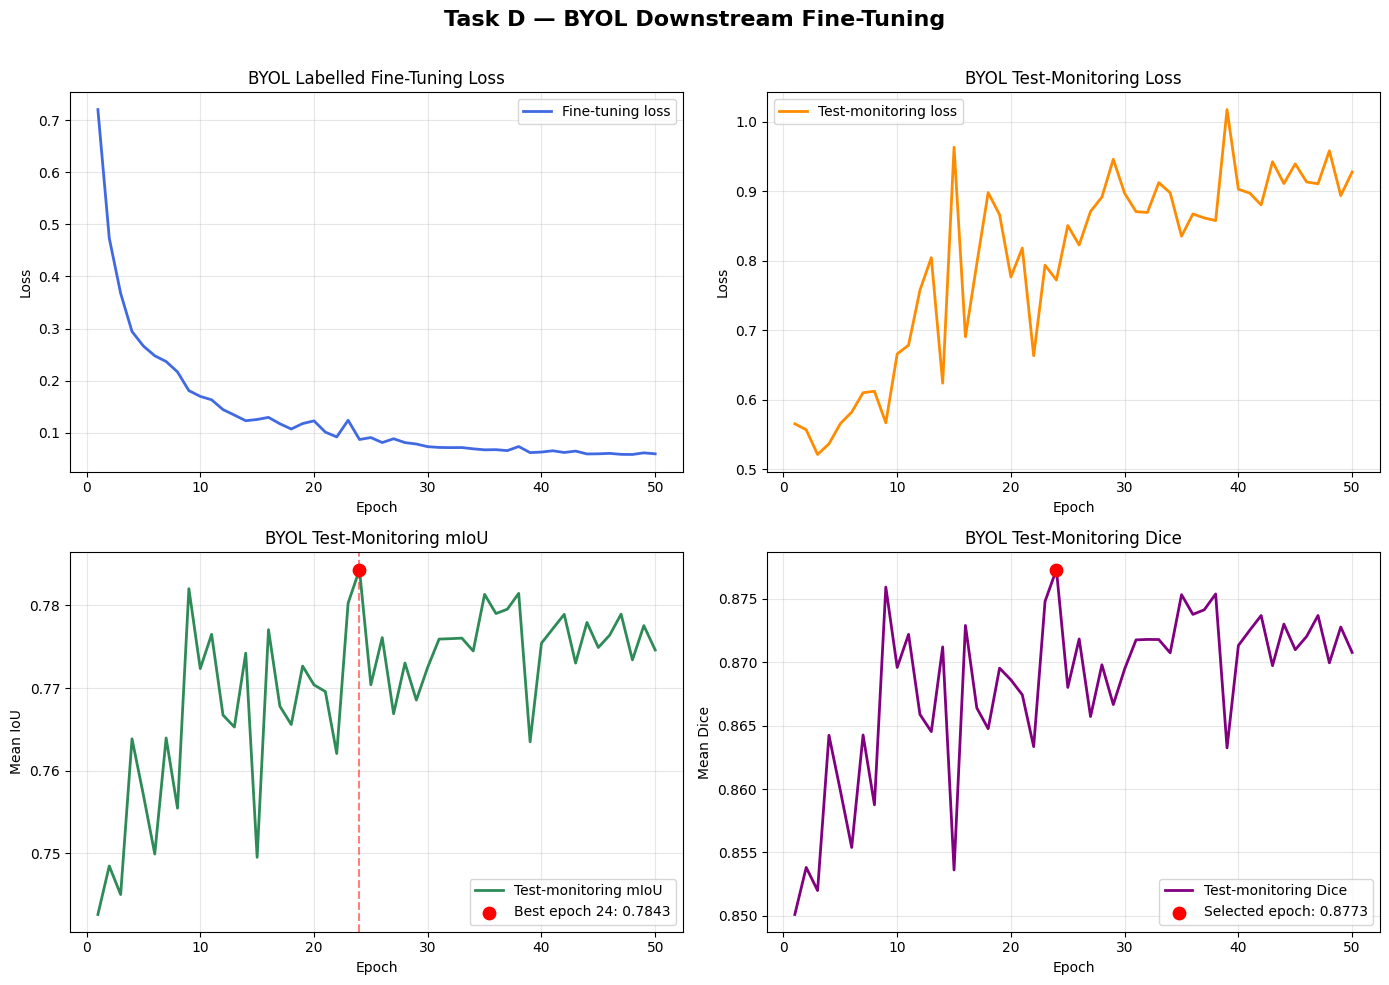

TASK D — CURVES COMPLETED

Best checkpoint epoch: 24
Best monitoring mIoU: 0.784341
Dice at selected checkpoint: 0.877294

Epoch-50 monitoring mIoU: 0.774605
Epoch-50 monitoring Dice: 0.870764

Average epoch time: 0.1612 minutes

Saved curve:
/kaggle/working/BYOL_Downstream_outputs/byol_task_d_finetune_curves.png

Task D is fully completed.


In [10]:
# ============================================================
# TASK D — SUPERVISED FINE-TUNING
# CELL 9 — TRAINING AND MONITORING CURVES
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Reload and validate the 50-epoch history
# ------------------------------------------------------------

history_df = pd.read_csv(
    HISTORY_PATH
)

assert len(history_df) == FINETUNE_EPOCHS

assert history_df["epoch"].astype(
    int
).tolist() == list(
    range(1, FINETUNE_EPOCHS + 1)
)

required_history_columns = {
    "epoch",
    "train_loss",
    "test_monitoring_loss",
    "test_monitoring_miou",
    "test_monitoring_dice",
    "test_monitoring_pixel_accuracy",
    "epoch_time_minutes",
}

missing_history_columns = (
    required_history_columns
    - set(history_df.columns)
)

assert not missing_history_columns, (
    f"Missing history columns: "
    f"{sorted(missing_history_columns)}"
)

# ------------------------------------------------------------
# 2. Identify best and final epochs
# ------------------------------------------------------------

calculated_best_index = (
    history_df[
        "test_monitoring_miou"
    ].idxmax()
)

calculated_best_epoch = int(
    history_df.loc[
        calculated_best_index,
        "epoch",
    ]
)

calculated_best_miou = float(
    history_df.loc[
        calculated_best_index,
        "test_monitoring_miou",
    ]
)

assert calculated_best_epoch == best_epoch

# ------------------------------------------------------------
# 3. Plot required Task-D curves
# ------------------------------------------------------------

figure, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10),
)

# Labelled fine-tuning loss
axes[0, 0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    color="royalblue",
    linewidth=2,
    label="Fine-tuning loss",
)

axes[0, 0].set_title(
    "BYOL Labelled Fine-Tuning Loss"
)

axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()

# Test-monitoring loss
axes[0, 1].plot(
    history_df["epoch"],
    history_df[
        "test_monitoring_loss"
    ],
    color="darkorange",
    linewidth=2,
    label="Test-monitoring loss",
)

axes[0, 1].set_title(
    "BYOL Test-Monitoring Loss"
)

axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].grid(alpha=0.3)
axes[0, 1].legend()

# Test-monitoring mIoU
axes[1, 0].plot(
    history_df["epoch"],
    history_df[
        "test_monitoring_miou"
    ],
    color="seagreen",
    linewidth=2,
    label="Test-monitoring mIoU",
)

axes[1, 0].scatter(
    [calculated_best_epoch],
    [calculated_best_miou],
    color="red",
    s=80,
    zorder=3,
    label=(
        f"Best epoch {calculated_best_epoch}: "
        f"{calculated_best_miou:.4f}"
    ),
)

axes[1, 0].axvline(
    calculated_best_epoch,
    color="red",
    linestyle="--",
    alpha=0.5,
)

axes[1, 0].set_title(
    "BYOL Test-Monitoring mIoU"
)

axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Mean IoU")
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend()

# Test-monitoring Dice
axes[1, 1].plot(
    history_df["epoch"],
    history_df[
        "test_monitoring_dice"
    ],
    color="purple",
    linewidth=2,
    label="Test-monitoring Dice",
)

best_dice_at_best_miou = float(
    history_df.loc[
        calculated_best_index,
        "test_monitoring_dice",
    ]
)

axes[1, 1].scatter(
    [calculated_best_epoch],
    [best_dice_at_best_miou],
    color="red",
    s=80,
    zorder=3,
    label=(
        f"Selected epoch: "
        f"{best_dice_at_best_miou:.4f}"
    ),
)

axes[1, 1].set_title(
    "BYOL Test-Monitoring Dice"
)

axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Mean Dice")
axes[1, 1].grid(alpha=0.3)
axes[1, 1].legend()

figure.suptitle(
    "Task D — BYOL Downstream Fine-Tuning",
    fontsize=16,
    fontweight="bold",
)

plt.tight_layout(
    rect=(0, 0, 1, 0.97)
)

CURVES_PATH = (
    OUTPUT_ROOT
    / "byol_task_d_finetune_curves.png"
)

plt.savefig(
    CURVES_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 4. Task-D curve summary
# ------------------------------------------------------------

epoch50_row = history_df.iloc[-1]

print("TASK D — CURVES COMPLETED")

print(
    "\nBest checkpoint epoch:",
    calculated_best_epoch,
)

print(
    "Best monitoring mIoU:",
    f"{calculated_best_miou:.6f}",
)

print(
    "Dice at selected checkpoint:",
    f"{best_dice_at_best_miou:.6f}",
)

print(
    "\nEpoch-50 monitoring mIoU:",
    f"{epoch50_row['test_monitoring_miou']:.6f}",
)

print(
    "Epoch-50 monitoring Dice:",
    f"{epoch50_row['test_monitoring_dice']:.6f}",
)

print(
    "\nAverage epoch time:",
    f"{history_df['epoch_time_minutes'].mean():.4f} minutes",
)

print("\nSaved curve:")
print(CURVES_PATH)

print(
    "\nTask D is fully completed."
)

In [11]:
# ============================================================
# TASK E — FINAL TESTING AND METRICS
# CELL 10 — LOAD BEST CHECKPOINT AND EVALUATE TEST SPLIT
# ============================================================

import json
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Verify and load the best Task-D checkpoint
# ------------------------------------------------------------

assert BEST_CHECKPOINT_PATH.exists(), (
    "The best Task-D checkpoint was not found."
)

try:
    best_checkpoint = torch.load(
        BEST_CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=False,
    )
except TypeError:
    best_checkpoint = torch.load(
        BEST_CHECKPOINT_PATH,
        map_location=DEVICE,
    )

required_best_checkpoint_keys = {
    "epoch",
    "model_state_dict",
    "best_monitoring_miou",
    "monitoring_metrics",
}

missing_best_checkpoint_keys = (
    required_best_checkpoint_keys
    - set(best_checkpoint.keys())
)

assert not missing_best_checkpoint_keys, (
    f"Missing checkpoint keys: "
    f"{sorted(missing_best_checkpoint_keys)}"
)

# ------------------------------------------------------------
# 2. Restore the selected BYOL segmentation model
# ------------------------------------------------------------

byol_segmentation_model.load_state_dict(
    best_checkpoint["model_state_dict"],
    strict=True,
)

byol_segmentation_model = (
    byol_segmentation_model.to(DEVICE)
)

byol_segmentation_model.eval()

SELECTED_CHECKPOINT_EPOCH = int(
    best_checkpoint["epoch"]
)

assert SELECTED_CHECKPOINT_EPOCH == best_epoch

# ------------------------------------------------------------
# 3. Final test evaluation
# ------------------------------------------------------------

final_test_metrics, final_test_predictions_df, final_confusion = (
    evaluate_segmentation(
        model=byol_segmentation_model,
        data_loader=test_loader,
        split_name="final_test",
        collect_per_image=True,
    )
)

assert len(final_test_predictions_df) == len(
    test_dataset
)

assert final_confusion.shape == (
    NUM_CLASSES,
    NUM_CLASSES,
)

assert np.isfinite(
    final_test_metrics["loss"]
)

assert np.isfinite(
    final_test_metrics["mean_iou"]
)

assert np.isfinite(
    final_test_metrics["mean_dice"]
)

# ------------------------------------------------------------
# 4. Confirm final evaluation matches checkpoint monitoring
# ------------------------------------------------------------

checkpoint_miou = float(
    best_checkpoint["best_monitoring_miou"]
)

evaluation_miou = float(
    final_test_metrics["mean_iou"]
)

assert np.isclose(
    checkpoint_miou,
    evaluation_miou,
    atol=1e-6,
), (
    f"Final mIoU {evaluation_miou:.8f} "
    f"does not match checkpoint mIoU "
    f"{checkpoint_miou:.8f}."
)

# ------------------------------------------------------------
# 5. Save Task-E outputs
# ------------------------------------------------------------

FINAL_METRICS_JSON_PATH = (
    OUTPUT_ROOT
    / "byol_final_test_metrics.json"
)

FINAL_METRICS_CSV_PATH = (
    OUTPUT_ROOT
    / "byol_final_test_metrics.csv"
)

FINAL_PREDICTIONS_PATH = (
    OUTPUT_ROOT
    / "byol_final_test_per_image_metrics.csv"
)

FINAL_CONFUSION_PATH = (
    OUTPUT_ROOT
    / "byol_final_confusion_matrix.csv"
)

final_metrics_package = {
    "task": "Assignment Part B - Task E",
    "method": "BYOL",
    "ssl_family": "Negative-free self-prediction",
    "backbone": "ResNet50",
    "decoder": "DeepLabV3-ASPP",
    "encoder_mode": ENCODER_MODE,

    "ssl_pretraining_epochs": 50,
    "downstream_finetuning_epochs": 50,
    "selected_checkpoint_epoch": (
        SELECTED_CHECKPOINT_EPOCH
    ),

    "unlabelled_pretraining_count": int(
        len(train_ssl_df)
    ),
    "labelled_finetuning_count": int(
        len(val_finetune_df)
    ),
    "test_count": int(
        len(test_eval_df)
    ),

    "test_loss": float(
        final_test_metrics["loss"]
    ),
    "mean_iou": float(
        final_test_metrics["mean_iou"]
    ),
    "mean_dice": float(
        final_test_metrics["mean_dice"]
    ),
    "pixel_accuracy": float(
        final_test_metrics[
            "overall_pixel_accuracy"
        ]
    ),

    "per_class_iou": {
        class_name: float(value)
        for class_name, value
        in final_test_metrics[
            "per_class_iou"
        ].items()
    },

    "per_class_dice": {
        class_name: float(value)
        for class_name, value
        in final_test_metrics[
            "per_class_dice"
        ].items()
    },

    "test_split_double_role": (
        "The Part-A test split was used for "
        "checkpoint monitoring during Task D and "
        "for final evaluation during Task E, as "
        "specified by the assignment."
    ),

    "best_checkpoint": str(
        BEST_CHECKPOINT_PATH
    ),
}

with FINAL_METRICS_JSON_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        final_metrics_package,
        file,
        indent=2,
    )

metrics_table = pd.DataFrame([
    {
        "metric": "Test Loss",
        "value": final_test_metrics["loss"],
    },
    {
        "metric": "Mean IoU",
        "value": final_test_metrics["mean_iou"],
    },
    {
        "metric": "Mean Dice",
        "value": final_test_metrics["mean_dice"],
    },
    {
        "metric": "Pixel Accuracy",
        "value": final_test_metrics[
            "overall_pixel_accuracy"
        ],
    },
    {
        "metric": "Background IoU",
        "value": final_test_metrics[
            "per_class_iou"
        ]["background"],
    },
    {
        "metric": "Landing-site IoU",
        "value": final_test_metrics[
            "per_class_iou"
        ]["landing_site"],
    },
    {
        "metric": "Background Dice",
        "value": final_test_metrics[
            "per_class_dice"
        ]["background"],
    },
    {
        "metric": "Landing-site Dice",
        "value": final_test_metrics[
            "per_class_dice"
        ]["landing_site"],
    },
])

metrics_table.to_csv(
    FINAL_METRICS_CSV_PATH,
    index=False,
)

final_test_predictions_df.to_csv(
    FINAL_PREDICTIONS_PATH,
    index=False,
)

confusion_dataframe = pd.DataFrame(
    final_confusion,
    index=[
        "true_background",
        "true_landing_site",
    ],
    columns=[
        "pred_background",
        "pred_landing_site",
    ],
)

confusion_dataframe.to_csv(
    FINAL_CONFUSION_PATH
)

# ------------------------------------------------------------
# 6. Display final Task-E results
# ------------------------------------------------------------

print("=" * 72)
print("TASK E — BYOL FINAL TEST RESULTS")
print("=" * 72)

print(
    "Selected checkpoint epoch:",
    SELECTED_CHECKPOINT_EPOCH,
)

print(
    "Test loss:",
    f"{final_test_metrics['loss']:.6f}",
)

print(
    "Mean IoU:",
    f"{final_test_metrics['mean_iou']:.6f}",
)

print(
    "Mean Dice:",
    f"{final_test_metrics['mean_dice']:.6f}",
)

print(
    "Pixel Accuracy:",
    f"{final_test_metrics['overall_pixel_accuracy']:.6f}",
)

print("\nPer-class IoU:")

for class_name, value in (
    final_test_metrics[
        "per_class_iou"
    ].items()
):
    print(
        f"{class_name}: {value:.6f}"
    )

print("\nPer-class Dice:")

for class_name, value in (
    final_test_metrics[
        "per_class_dice"
    ].items()
):
    print(
        f"{class_name}: {value:.6f}"
    )

print("\nConfusion matrix:")
print(confusion_dataframe)

print("\nSaved Task-E files:")
print(FINAL_METRICS_JSON_PATH)
print(FINAL_METRICS_CSV_PATH)
print(FINAL_PREDICTIONS_PATH)
print(FINAL_CONFUSION_PATH)

print(
    "\nTask E final evaluation completed."
)

Evaluate final_test:   0%|          | 0/23 [00:00<?, ?it/s]

TASK E — BYOL FINAL TEST RESULTS
Selected checkpoint epoch: 24
Test loss: 0.771905
Mean IoU: 0.784341
Mean Dice: 0.877294
Pixel Accuracy: 0.894172

Per-class IoU:
background: 0.856671
landing_site: 0.712012

Per-class Dice:
background: 0.922803
landing_site: 0.831784

Confusion matrix:
                   pred_background  pred_landing_site
true_background           14923191            1278710
true_landing_site          1218080            6172979

Saved Task-E files:
/kaggle/working/BYOL_Downstream_outputs/byol_final_test_metrics.json
/kaggle/working/BYOL_Downstream_outputs/byol_final_test_metrics.csv
/kaggle/working/BYOL_Downstream_outputs/byol_final_test_per_image_metrics.csv
/kaggle/working/BYOL_Downstream_outputs/byol_final_confusion_matrix.csv

Task E final evaluation completed.


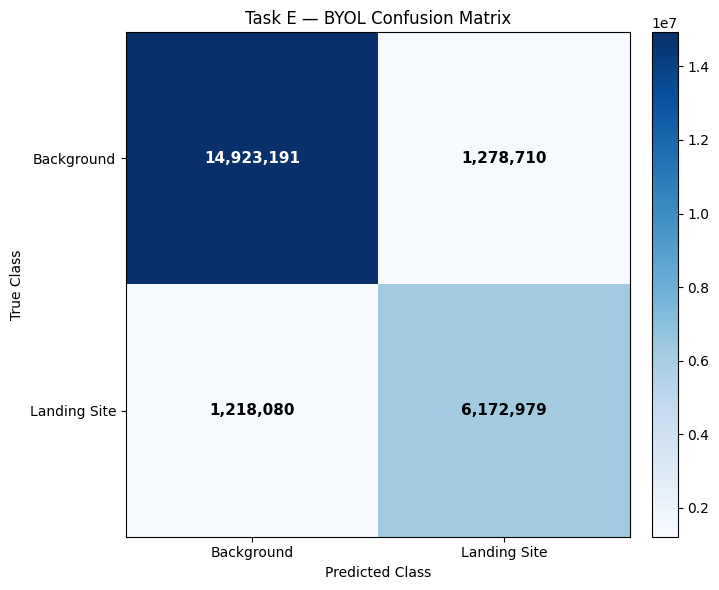

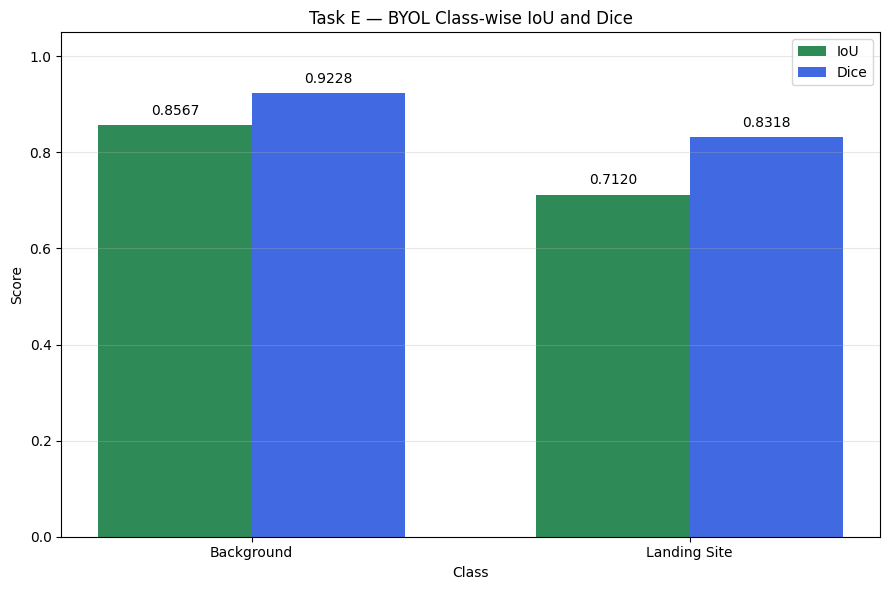

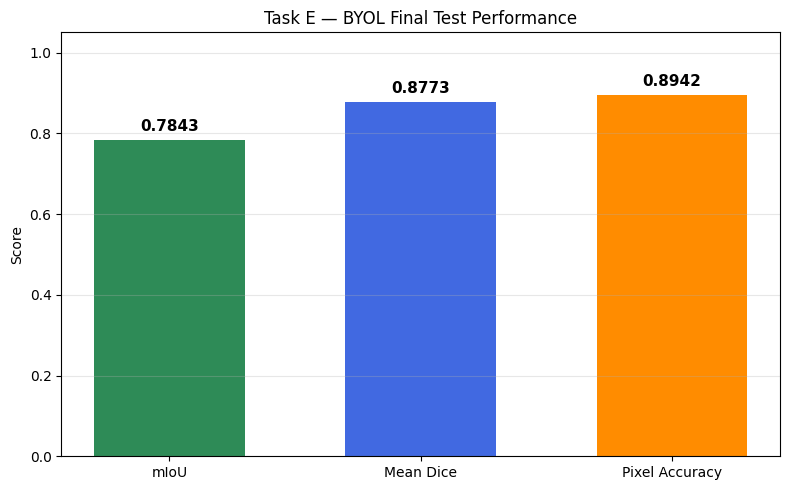

TASK E — VISUALIZATIONS COMPLETED

Confusion matrix:
[[14923191  1278710]
 [ 1218080  6172979]]

Class-wise scores:
Background | IoU=0.856671 | Dice=0.922803
Landing Site | IoU=0.712012 | Dice=0.831784

Saved plots:
/kaggle/working/BYOL_Downstream_outputs/byol_task_e_confusion_matrix.png
/kaggle/working/BYOL_Downstream_outputs/byol_task_e_classwise_iou_dice.png
/kaggle/working/BYOL_Downstream_outputs/byol_task_e_overall_metrics.png

Task E metric visualizations completed.


In [12]:
# ============================================================
# TASK E — FINAL TESTING AND METRICS
# CELL 11 — CONFUSION MATRIX AND CLASS-WISE METRIC PLOTS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Confusion-matrix heatmap
# ------------------------------------------------------------

confusion_array = np.asarray(
    final_confusion,
    dtype=np.int64,
)

class_names = [
    "Background",
    "Landing Site",
]

CONFUSION_PLOT_PATH = (
    OUTPUT_ROOT
    / "byol_task_e_confusion_matrix.png"
)

figure, axis = plt.subplots(
    figsize=(7, 6)
)

image = axis.imshow(
    confusion_array,
    interpolation="nearest",
    cmap="Blues",
)

figure.colorbar(
    image,
    ax=axis,
    fraction=0.046,
    pad=0.04,
)

axis.set(
    xticks=np.arange(NUM_CLASSES),
    yticks=np.arange(NUM_CLASSES),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted Class",
    ylabel="True Class",
    title="Task E — BYOL Confusion Matrix",
)

threshold = (
    confusion_array.max() / 2.0
)

for row_index in range(NUM_CLASSES):
    for column_index in range(NUM_CLASSES):
        value = confusion_array[
            row_index,
            column_index,
        ]

        axis.text(
            column_index,
            row_index,
            f"{value:,}",
            horizontalalignment="center",
            verticalalignment="center",
            color=(
                "white"
                if value > threshold
                else "black"
            ),
            fontsize=11,
            fontweight="bold",
        )

plt.tight_layout()

plt.savefig(
    CONFUSION_PLOT_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 2. Class-wise IoU and Dice chart
# ------------------------------------------------------------

class_iou_values = [
    final_test_metrics[
        "per_class_iou"
    ]["background"],

    final_test_metrics[
        "per_class_iou"
    ]["landing_site"],
]

class_dice_values = [
    final_test_metrics[
        "per_class_dice"
    ]["background"],

    final_test_metrics[
        "per_class_dice"
    ]["landing_site"],
]

CLASS_METRICS_PLOT_PATH = (
    OUTPUT_ROOT
    / "byol_task_e_classwise_iou_dice.png"
)

positions = np.arange(
    len(class_names)
)

bar_width = 0.35

figure, axis = plt.subplots(
    figsize=(9, 6)
)

iou_bars = axis.bar(
    positions - bar_width / 2,
    class_iou_values,
    width=bar_width,
    label="IoU",
    color="seagreen",
)

dice_bars = axis.bar(
    positions + bar_width / 2,
    class_dice_values,
    width=bar_width,
    label="Dice",
    color="royalblue",
)

axis.set_title(
    "Task E — BYOL Class-wise IoU and Dice"
)

axis.set_xlabel("Class")
axis.set_ylabel("Score")

axis.set_xticks(positions)
axis.set_xticklabels(class_names)

axis.set_ylim(0.0, 1.05)
axis.grid(
    axis="y",
    alpha=0.3,
)

axis.legend()

for bars in [
    iou_bars,
    dice_bars,
]:
    for bar in bars:
        height = bar.get_height()

        axis.text(
            bar.get_x()
            + bar.get_width() / 2,
            height + 0.015,
            f"{height:.4f}",
            ha="center",
            va="bottom",
            fontsize=10,
        )

plt.tight_layout()

plt.savefig(
    CLASS_METRICS_PLOT_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 3. Overall metric summary chart
# ------------------------------------------------------------

overall_metric_names = [
    "mIoU",
    "Mean Dice",
    "Pixel Accuracy",
]

overall_metric_values = [
    final_test_metrics["mean_iou"],
    final_test_metrics["mean_dice"],
    final_test_metrics[
        "overall_pixel_accuracy"
    ],
]

OVERALL_METRICS_PLOT_PATH = (
    OUTPUT_ROOT
    / "byol_task_e_overall_metrics.png"
)

figure, axis = plt.subplots(
    figsize=(8, 5)
)

bars = axis.bar(
    overall_metric_names,
    overall_metric_values,
    color=[
        "seagreen",
        "royalblue",
        "darkorange",
    ],
    width=0.6,
)

axis.set_title(
    "Task E — BYOL Final Test Performance"
)

axis.set_ylabel("Score")
axis.set_ylim(0.0, 1.05)
axis.grid(
    axis="y",
    alpha=0.3,
)

for bar, value in zip(
    bars,
    overall_metric_values,
):
    axis.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

plt.tight_layout()

plt.savefig(
    OVERALL_METRICS_PLOT_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 4. Plot summary
# ------------------------------------------------------------

print("TASK E — VISUALIZATIONS COMPLETED")

print("\nConfusion matrix:")
print(confusion_array)

print("\nClass-wise scores:")

for index, class_name in enumerate(
    class_names
):
    print(
        f"{class_name} | "
        f"IoU={class_iou_values[index]:.6f} | "
        f"Dice={class_dice_values[index]:.6f}"
    )

print("\nSaved plots:")
print(CONFUSION_PLOT_PATH)
print(CLASS_METRICS_PLOT_PATH)
print(OVERALL_METRICS_PLOT_PATH)

print(
    "\nTask E metric visualizations completed."
)

In [13]:
# ============================================================
# TASK E — LABEL-EFFICIENCY COMPARISON
# CELL 12 — CREATE STANDARD BYOL COMPARISON PACKAGE
# ============================================================

import json
import shutil
from pathlib import Path

import pandas as pd

# ------------------------------------------------------------
# 1. Label-efficiency information
# ------------------------------------------------------------

PARTA_FULLY_SUPERVISED_LABEL_COUNT = int(
    len(train_ssl_df)
)

BYOL_LABELLED_FINETUNE_COUNT = int(
    len(val_finetune_df)
)

LABELLED_RATIO_VS_PARTA = float(
    BYOL_LABELLED_FINETUNE_COUNT
    / PARTA_FULLY_SUPERVISED_LABEL_COUNT
)

LABEL_REDUCTION_PERCENT = float(
    (
        1.0
        - LABELLED_RATIO_VS_PARTA
    )
    * 100.0
)

# ------------------------------------------------------------
# 2. Standard BYOL result row
# ------------------------------------------------------------

byol_comparison_result = {
    "method": "BYOL",
    "ssl_family": (
        "Negative-free self-prediction"
    ),
    "official_checkpoint": (
        byol_checkpoint.get(
            "pretrained_source",
            "BYOL ImageNet-pretrained ResNet50",
        )
    ),
    "backbone": "ResNet50",
    "decoder": "DeepLabV3-ASPP",
    "encoder_mode": ENCODER_MODE,

    "ssl_epochs_completed": 50,
    "finetune_epochs_completed": 50,
    "best_checkpoint_epoch": int(
        SELECTED_CHECKPOINT_EPOCH
    ),

    "ssl_unlabelled_train_count": int(
        len(train_ssl_df)
    ),
    "ssl_labelled_finetune_count": (
        BYOL_LABELLED_FINETUNE_COUNT
    ),
    "test_count": int(
        len(test_eval_df)
    ),

    "parta_fully_supervised_label_count": (
        PARTA_FULLY_SUPERVISED_LABEL_COUNT
    ),

    "labelled_ratio_vs_parta_train": (
        LABELLED_RATIO_VS_PARTA
    ),

    "label_reduction_percent": (
        LABEL_REDUCTION_PERCENT
    ),

    "test_loss": float(
        final_test_metrics["loss"]
    ),

    "mean_iou": float(
        final_test_metrics["mean_iou"]
    ),

    "mean_dice": float(
        final_test_metrics["mean_dice"]
    ),

    "pixel_accuracy": float(
        final_test_metrics[
            "overall_pixel_accuracy"
        ]
    ),

    "background_iou": float(
        final_test_metrics[
            "per_class_iou"
        ]["background"]
    ),

    "landing_site_iou": float(
        final_test_metrics[
            "per_class_iou"
        ]["landing_site"]
    ),

    "background_dice": float(
        final_test_metrics[
            "per_class_dice"
        ]["background"]
    ),

    "landing_site_dice": float(
        final_test_metrics[
            "per_class_dice"
        ]["landing_site"]
    ),

    "epoch50_test_miou": float(
        history_df.iloc[-1][
            "test_monitoring_miou"
        ]
    ),

    "epoch50_test_dice": float(
        history_df.iloc[-1][
            "test_monitoring_dice"
        ]
    ),

    "mean_ssl_epoch_minutes": float(
        byol_checkpoint.get(
            "config",
            {},
        ).get(
            "average_epoch_time_minutes",
            1.3326915645,
        )
    ),

    "mean_downstream_epoch_minutes": float(
        history_df[
            "epoch_time_minutes"
        ].mean()
    ),

    "test_split_double_role": True,

    "best_checkpoint_file": (
        BEST_CHECKPOINT_PATH.name
    ),

    "notes": (
        "BYOL SSL pretraining used the Part-A "
        "train split without labels. DeepLabV3-ASPP "
        "was fine-tuned using only the Part-A "
        "validation split and monitored/evaluated "
        "on the Part-A test split."
    ),
}

# ------------------------------------------------------------
# 3. Save comparison CSV and JSON
# ------------------------------------------------------------

BYOL_COMPARISON_CSV_PATH = (
    COMPARISON_ROOT
    / "byol_comparison_result.csv"
)

BYOL_COMPARISON_JSON_PATH = (
    COMPARISON_ROOT
    / "byol_comparison_result.json"
)

pd.DataFrame([
    byol_comparison_result
]).to_csv(
    BYOL_COMPARISON_CSV_PATH,
    index=False,
)

with BYOL_COMPARISON_JSON_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        byol_comparison_result,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 4. Create standard results.json
# ------------------------------------------------------------

RESULTS_JSON_PATH = (
    COMPARISON_ROOT
    / "results.json"
)

standard_results = {
    "BYOL": byol_comparison_result
}

with RESULTS_JSON_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        standard_results,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 5. Copy compact supporting artifacts
# ------------------------------------------------------------

supporting_files = [
    FINAL_METRICS_JSON_PATH,
    FINAL_METRICS_CSV_PATH,
    FINAL_CONFUSION_PATH,
    HISTORY_PATH,
    CURVES_PATH,
    CONFUSION_PLOT_PATH,
    CLASS_METRICS_PLOT_PATH,
    OVERALL_METRICS_PLOT_PATH,
    TRAINING_SUMMARY_PATH,
    CONFIG_PATH,
]

copied_files = []

for source_path in supporting_files:
    source_path = Path(source_path)

    if source_path.exists():
        destination_path = (
            COMPARISON_ROOT
            / source_path.name
        )

        if (
            source_path.resolve()
            != destination_path.resolve()
        ):
            shutil.copy2(
                source_path,
                destination_path,
            )

        copied_files.append(
            destination_path
        )

# ------------------------------------------------------------
# 6. Create compact ZIP package
# ------------------------------------------------------------

BYOL_COMPARISON_ZIP_BASE = (
    OUTPUT_ROOT
    / "byol_final_comparison_input"
)

BYOL_COMPARISON_ZIP_PATH = Path(
    shutil.make_archive(
        str(BYOL_COMPARISON_ZIP_BASE),
        "zip",
        root_dir=COMPARISON_ROOT,
    )
)

assert BYOL_COMPARISON_ZIP_PATH.exists()

# ------------------------------------------------------------
# 7. Display label-efficiency summary
# ------------------------------------------------------------

print("=" * 72)
print("TASK E — BYOL COMPARISON PACKAGE")
print("=" * 72)

print(
    "Part-A labelled training images:",
    PARTA_FULLY_SUPERVISED_LABEL_COUNT,
)

print(
    "BYOL labelled fine-tuning images:",
    BYOL_LABELLED_FINETUNE_COUNT,
)

print(
    "Labelled-data ratio:",
    f"{LABELLED_RATIO_VS_PARTA:.6f}",
)

print(
    "Labelled-data percentage:",
    f"{LABELLED_RATIO_VS_PARTA * 100:.2f}%",
)

print(
    "Label reduction:",
    f"{LABEL_REDUCTION_PERCENT:.2f}%",
)

print(
    "\nBYOL final mIoU:",
    f"{byol_comparison_result['mean_iou']:.6f}",
)

print(
    "BYOL final Dice:",
    f"{byol_comparison_result['mean_dice']:.6f}",
)

print("\nComparison CSV:")
print(BYOL_COMPARISON_CSV_PATH)

print("\nComparison JSON:")
print(BYOL_COMPARISON_JSON_PATH)

print("\nStandard results.json:")
print(RESULTS_JSON_PATH)

print("\nCompact comparison ZIP:")
print(BYOL_COMPARISON_ZIP_PATH)

print(
    "\nTask E comparison package completed."
)

TASK E — BYOL COMPARISON PACKAGE
Part-A labelled training images: 1416
BYOL labelled fine-tuning images: 314
Labelled-data ratio: 0.221751
Labelled-data percentage: 22.18%
Label reduction: 77.82%

BYOL final mIoU: 0.784341
BYOL final Dice: 0.877294

Comparison CSV:
/kaggle/working/BYOL_Downstream_outputs/final_comparison_input/byol_comparison_result.csv

Comparison JSON:
/kaggle/working/BYOL_Downstream_outputs/final_comparison_input/byol_comparison_result.json

Standard results.json:
/kaggle/working/BYOL_Downstream_outputs/final_comparison_input/results.json

Compact comparison ZIP:
/kaggle/working/BYOL_Downstream_outputs/byol_final_comparison_input.zip

Task E comparison package completed.


In [14]:
# ============================================================
# TASK F — ERROR ANALYSIS
# CELL 13 — IDENTIFY LOWEST-IoU TEST IMAGES
# ============================================================

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Verify Task-E per-image results
# ------------------------------------------------------------

assert len(final_test_predictions_df) == len(
    test_eval_df
)

required_per_image_columns = {
    "image_id",
    "mean_iou",
    "mean_dice",
    "pixel_accuracy",
    "background_iou",
    "landing_site_iou",
}

missing_per_image_columns = (
    required_per_image_columns
    - set(final_test_predictions_df.columns)
)

assert not missing_per_image_columns, (
    f"Missing per-image columns: "
    f"{sorted(missing_per_image_columns)}"
)

# ------------------------------------------------------------
# 2. Add image paths, mask paths, and GT information
# ------------------------------------------------------------

test_metadata = test_eval_df.copy()

test_metadata["image_id"] = (
    test_metadata["image_id"].astype(str)
)

error_analysis_df = (
    final_test_predictions_df.copy()
)

error_analysis_df["image_id"] = (
    error_analysis_df["image_id"].astype(str)
)

error_analysis_df = error_analysis_df.merge(
    test_metadata[
        [
            "image_id",
            "image_relpath",
            "encoded_mask_relpath",
        ]
    ],
    on="image_id",
    how="left",
    validate="one_to_one",
)

assert error_analysis_df[
    "image_relpath"
].notna().all()

assert error_analysis_df[
    "encoded_mask_relpath"
].notna().all()

# ------------------------------------------------------------
# 3. Calculate ground-truth foreground information
# ------------------------------------------------------------

ground_truth_records = []

for row in tqdm(
    error_analysis_df.itertuples(index=False),
    total=len(error_analysis_df),
    desc="Inspecting test ground-truth masks",
):
    mask_path = (
        PARTA_NB0_ROOT
        / row.encoded_mask_relpath
    )

    mask = read_encoded_mask(mask_path)

    foreground_pixels = int(
        (mask == 1).sum()
    )

    total_pixels = int(mask.size)

    foreground_fraction = float(
        foreground_pixels
        / max(total_pixels, 1)
    )

    ground_truth_records.append({
        "image_id": str(row.image_id),
        "gt_foreground_pixels": (
            foreground_pixels
        ),
        "gt_foreground_fraction": (
            foreground_fraction
        ),
        "gt_has_landing_site": bool(
            foreground_pixels > 0
        ),
    })

ground_truth_df = pd.DataFrame(
    ground_truth_records
)

error_analysis_df = (
    error_analysis_df.merge(
        ground_truth_df,
        on="image_id",
        how="left",
        validate="one_to_one",
    )
)

# ------------------------------------------------------------
# 4. Sort by lowest per-image mIoU
# ------------------------------------------------------------

NUMBER_OF_WORST_IMAGES = 8

worst_images_df = (
    error_analysis_df
    .sort_values(
        by=[
            "mean_iou",
            "landing_site_iou",
        ],
        ascending=[
            True,
            True,
        ],
    )
    .head(NUMBER_OF_WORST_IMAGES)
    .reset_index(drop=True)
)

worst_images_df.insert(
    0,
    "error_rank",
    np.arange(
        1,
        len(worst_images_df) + 1,
    ),
)

# ------------------------------------------------------------
# 5. Save Task-F tables
# ------------------------------------------------------------

ALL_PER_IMAGE_RESULTS_PATH = (
    OUTPUT_ROOT
    / "byol_task_f_all_test_images.csv"
)

WORST_IMAGES_PATH = (
    OUTPUT_ROOT
    / "byol_task_f_worst_test_images.csv"
)

error_analysis_df.to_csv(
    ALL_PER_IMAGE_RESULTS_PATH,
    index=False,
)

worst_images_df.to_csv(
    WORST_IMAGES_PATH,
    index=False,
)

# ------------------------------------------------------------
# 6. Display worst cases
# ------------------------------------------------------------

display_columns = [
    "error_rank",
    "image_id",
    "mean_iou",
    "landing_site_iou",
    "background_iou",
    "mean_dice",
    "pixel_accuracy",
    "gt_foreground_fraction",
    "gt_has_landing_site",
]

print("=" * 72)
print("TASK F — WORST BYOL TEST IMAGES")
print("=" * 72)

display(
    worst_images_df[
        display_columns
    ]
)

print(
    "\nWorst mIoU:",
    f"{worst_images_df['mean_iou'].min():.6f}",
)

print(
    "Highest mIoU among selected worst cases:",
    f"{worst_images_df['mean_iou'].max():.6f}",
)

print(
    "\nSelected cases with a landing site:",
    int(
        worst_images_df[
            "gt_has_landing_site"
        ].sum()
    ),
    "/",
    len(worst_images_df),
)

print("\nSaved complete per-image table:")
print(ALL_PER_IMAGE_RESULTS_PATH)

print("\nSaved worst-image table:")
print(WORST_IMAGES_PATH)

print(
    "\nTask F worst-image identification completed."
)

Inspecting test ground-truth masks:   0%|          | 0/360 [00:00<?, ?it/s]

TASK F — WORST BYOL TEST IMAGES


,error_rank,image_id,mean_iou,landing_site_iou,background_iou,mean_dice,pixel_accuracy,gt_foreground_fraction,gt_has_landing_site
0,1,testing_00247,0.069434,0.039667,0.099201,0.128402,0.131516,0.039001,True
1,2,testing_00154,0.192703,0.000000,0.385406,0.278190,0.385406,0.000015,True
2,3,testing_00088,0.207199,0.000000,0.414398,0.292986,0.414398,0.585602,True
3,4,testing_00205,0.277784,0.027825,0.527744,0.372512,0.534042,0.475113,True
4,5,testing_00341,0.325321,0.256022,0.394620,0.486794,0.498993,0.613876,True
5,6,testing_00084,0.343200,0.012526,0.673873,0.414954,0.675217,0.268341,True
6,7,testing_00046,0.345154,0.000000,0.690308,0.408392,0.690308,0.000000,False
7,8,testing_00176,0.349003,0.223793,0.474213,0.504540,0.543427,0.134689,True



Worst mIoU: 0.069434
Highest mIoU among selected worst cases: 0.349003

Selected cases with a landing site: 7 / 8

Saved complete per-image table:
/kaggle/working/BYOL_Downstream_outputs/byol_task_f_all_test_images.csv

Saved worst-image table:
/kaggle/working/BYOL_Downstream_outputs/byol_task_f_worst_test_images.csv

Task F worst-image identification completed.


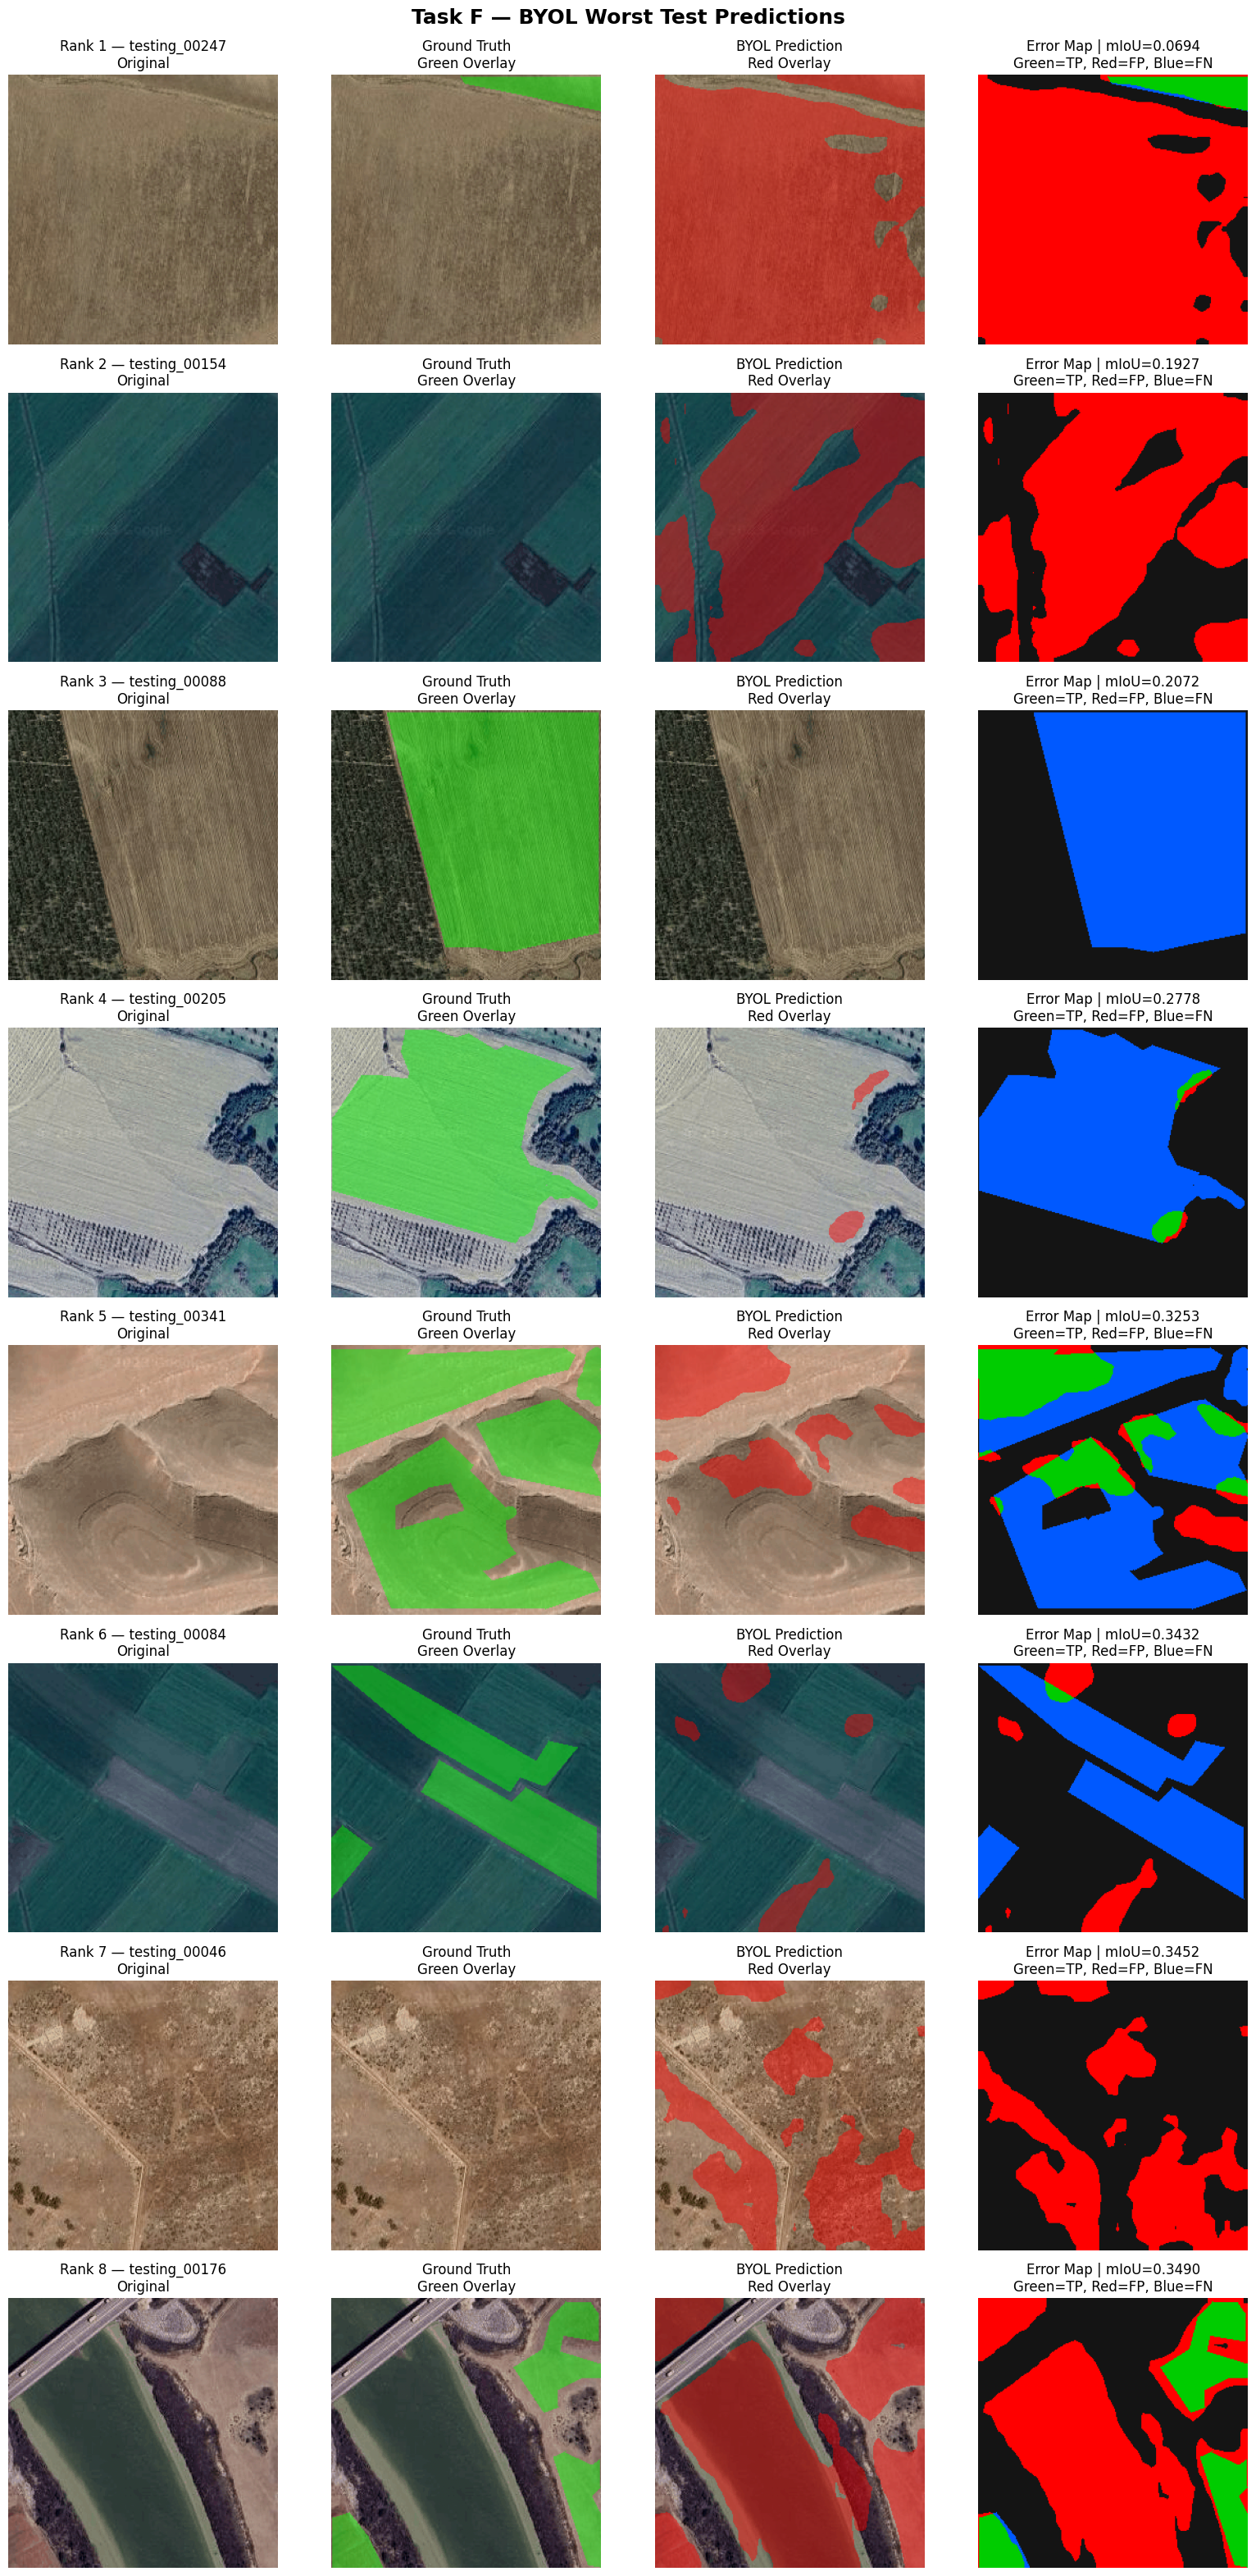

TASK F — VISUAL ERROR ANALYSIS COMPLETED


,error_rank,image_id,mean_iou,landing_site_iou,true_positive_pixels,false_positive_pixels,false_negative_pixels,predicted_foreground_fraction
0,1,testing_00247,0.069434,0.039667,2351,56784,205,0.902328
1,2,testing_00154,0.192703,0.000000,0,40263,1,0.614365
2,3,testing_00088,0.207199,0.000000,0,0,38378,0.000000
3,4,testing_00205,0.277784,0.027825,879,275,30258,0.017609
4,5,testing_00341,0.325321,0.256022,11313,3901,28918,0.232147
5,6,testing_00084,0.343200,0.012526,279,3940,17307,0.064377
6,7,testing_00046,0.345154,0.000000,0,20347,0,0.310471
7,8,testing_00176,0.349003,0.223793,8629,29723,198,0.585205



Combined visualization:
/kaggle/working/BYOL_Downstream_outputs/byol_task_f_worst_error_analysis.png

Individual figures folder:
/kaggle/working/BYOL_Downstream_outputs/byol_task_f_error_images

Numerical error details:
/kaggle/working/BYOL_Downstream_outputs/byol_task_f_worst_error_details.csv

Task F visualizations completed.


In [15]:
# ============================================================
# TASK F — ERROR ANALYSIS
# CELL 14 — VISUALIZE WORST TEST PREDICTIONS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from PIL import Image

# ------------------------------------------------------------
# 1. Output folder
# ------------------------------------------------------------

ERROR_IMAGE_ROOT = (
    OUTPUT_ROOT
    / "byol_task_f_error_images"
)

ERROR_IMAGE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

COMBINED_ERROR_PLOT_PATH = (
    OUTPUT_ROOT
    / "byol_task_f_worst_error_analysis.png"
)

# ------------------------------------------------------------
# 2. Visualization helpers
# ------------------------------------------------------------

def resize_rgb_for_display(
    image,
    size=IMAGE_SIZE,
):
    image = Image.fromarray(
        image.astype(np.uint8)
    )

    image = image.resize(
        (size, size),
        resample=Image.Resampling.BILINEAR,
    )

    return np.asarray(
        image,
        dtype=np.uint8,
    )


def resize_mask_for_display(
    mask,
    size=IMAGE_SIZE,
):
    mask = Image.fromarray(
        mask.astype(np.uint8)
    )

    mask = mask.resize(
        (size, size),
        resample=Image.Resampling.NEAREST,
    )

    return np.asarray(
        mask,
        dtype=np.uint8,
    )


def create_mask_overlay(
    image,
    mask,
    color,
    alpha=0.45,
):
    image_float = (
        image.astype(np.float32) / 255.0
    )

    overlay = image_float.copy()

    color_array = np.asarray(
        color,
        dtype=np.float32,
    )

    mask_area = mask == 1

    overlay[mask_area] = (
        (1.0 - alpha)
        * overlay[mask_area]
        + alpha
        * color_array
    )

    return np.clip(
        overlay,
        0.0,
        1.0,
    )


def create_error_map(
    ground_truth,
    prediction,
):
    # Black: true negative
    # Green: true positive
    # Red: false positive
    # Blue: false negative

    error_map = np.zeros(
        (
            ground_truth.shape[0],
            ground_truth.shape[1],
            3,
        ),
        dtype=np.float32,
    )

    true_positive = (
        (ground_truth == 1)
        & (prediction == 1)
    )

    false_positive = (
        (ground_truth == 0)
        & (prediction == 1)
    )

    false_negative = (
        (ground_truth == 1)
        & (prediction == 0)
    )

    true_negative = (
        (ground_truth == 0)
        & (prediction == 0)
    )

    error_map[true_negative] = [
        0.08,
        0.08,
        0.08,
    ]

    error_map[true_positive] = [
        0.0,
        0.8,
        0.0,
    ]

    error_map[false_positive] = [
        1.0,
        0.0,
        0.0,
    ]

    error_map[false_negative] = [
        0.0,
        0.35,
        1.0,
    ]

    return error_map

# ------------------------------------------------------------
# 3. Run inference on the selected worst cases
# ------------------------------------------------------------

byol_segmentation_model.eval()

visualization_records = []

for row in worst_images_df.itertuples(
    index=False
):
    image_path = (
        RAW_DATA_ROOT
        / row.image_relpath
    )

    mask_path = (
        PARTA_NB0_ROOT
        / row.encoded_mask_relpath
    )

    original_image = read_rgb_image(
        image_path
    )

    ground_truth_mask = read_encoded_mask(
        mask_path
    )

    transformed = test_transform(
        image=original_image,
        mask=ground_truth_mask,
    )

    input_tensor = (
        transformed["image"]
        .float()
        .unsqueeze(0)
        .to(
            DEVICE,
            non_blocking=True,
        )
    )

    with torch.no_grad():
        output = byol_segmentation_model(
            input_tensor
        )

        prediction = torch.argmax(
            output["out"],
            dim=1,
        )[0].cpu().numpy().astype(
            np.uint8
        )

    display_image = resize_rgb_for_display(
        original_image
    )

    display_ground_truth = (
        resize_mask_for_display(
            ground_truth_mask
        )
    )

    ground_truth_overlay = (
        create_mask_overlay(
            display_image,
            display_ground_truth,
            color=[0.0, 1.0, 0.0],
        )
    )

    prediction_overlay = create_mask_overlay(
        display_image,
        prediction,
        color=[1.0, 0.0, 0.0],
    )

    error_map = create_error_map(
        display_ground_truth,
        prediction,
    )

    true_positive_pixels = int(
        (
            (display_ground_truth == 1)
            & (prediction == 1)
        ).sum()
    )

    false_positive_pixels = int(
        (
            (display_ground_truth == 0)
            & (prediction == 1)
        ).sum()
    )

    false_negative_pixels = int(
        (
            (display_ground_truth == 1)
            & (prediction == 0)
        ).sum()
    )

    predicted_foreground_fraction = float(
        (prediction == 1).mean()
    )

    visualization_records.append({
        "error_rank": int(row.error_rank),
        "image_id": str(row.image_id),
        "mean_iou": float(row.mean_iou),
        "landing_site_iou": float(
            row.landing_site_iou
        ),
        "original_image": display_image,
        "ground_truth_overlay": (
            ground_truth_overlay
        ),
        "prediction_overlay": (
            prediction_overlay
        ),
        "error_map": error_map,
        "true_positive_pixels": (
            true_positive_pixels
        ),
        "false_positive_pixels": (
            false_positive_pixels
        ),
        "false_negative_pixels": (
            false_negative_pixels
        ),
        "predicted_foreground_fraction": (
            predicted_foreground_fraction
        ),
    })

# ------------------------------------------------------------
# 4. Create combined error-analysis grid
# ------------------------------------------------------------

number_of_cases = len(
    visualization_records
)

figure, axes = plt.subplots(
    number_of_cases,
    4,
    figsize=(
        16,
        4 * number_of_cases,
    ),
)

if number_of_cases == 1:
    axes = np.expand_dims(
        axes,
        axis=0,
    )

for row_index, record in enumerate(
    visualization_records
):
    axes[row_index, 0].imshow(
        record["original_image"]
    )

    axes[row_index, 0].set_title(
        f"Rank {record['error_rank']} — "
        f"{record['image_id']}\n"
        f"Original"
    )

    axes[row_index, 1].imshow(
        record["ground_truth_overlay"]
    )

    axes[row_index, 1].set_title(
        "Ground Truth\nGreen Overlay"
    )

    axes[row_index, 2].imshow(
        record["prediction_overlay"]
    )

    axes[row_index, 2].set_title(
        "BYOL Prediction\nRed Overlay"
    )

    axes[row_index, 3].imshow(
        record["error_map"]
    )

    axes[row_index, 3].set_title(
        f"Error Map | mIoU="
        f"{record['mean_iou']:.4f}\n"
        "Green=TP, Red=FP, Blue=FN"
    )

    for column_index in range(4):
        axes[row_index, column_index].axis(
            "off"
        )

figure.suptitle(
    "Task F — BYOL Worst Test Predictions",
    fontsize=18,
    fontweight="bold",
)

plt.tight_layout(
    rect=(0, 0, 1, 0.985)
)

plt.savefig(
    COMBINED_ERROR_PLOT_PATH,
    dpi=160,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 5. Save one figure per worst case
# ------------------------------------------------------------

for record in visualization_records:
    figure, axes = plt.subplots(
        1,
        4,
        figsize=(16, 4),
    )

    panels = [
        (
            record["original_image"],
            "Original Image",
        ),
        (
            record["ground_truth_overlay"],
            "Ground Truth",
        ),
        (
            record["prediction_overlay"],
            "BYOL Prediction",
        ),
        (
            record["error_map"],
            (
                "Error Map\n"
                "Green=TP, Red=FP, Blue=FN"
            ),
        ),
    ]

    for axis, (
        panel_image,
        panel_title,
    ) in zip(
        axes,
        panels,
    ):
        axis.imshow(panel_image)
        axis.set_title(panel_title)
        axis.axis("off")

    figure.suptitle(
        f"Rank {record['error_rank']} — "
        f"{record['image_id']} | "
        f"mIoU={record['mean_iou']:.4f}",
        fontsize=14,
        fontweight="bold",
    )

    plt.tight_layout(
        rect=(0, 0, 1, 0.92)
    )

    individual_path = (
        ERROR_IMAGE_ROOT
        / (
            f"rank_{record['error_rank']:02d}_"
            f"{record['image_id']}.png"
        )
    )

    plt.savefig(
        individual_path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.close(figure)

# ------------------------------------------------------------
# 6. Save numerical error details
# ------------------------------------------------------------

error_detail_records = []

for record in visualization_records:
    error_detail_records.append({
        "error_rank": record["error_rank"],
        "image_id": record["image_id"],
        "mean_iou": record["mean_iou"],
        "landing_site_iou": (
            record["landing_site_iou"]
        ),
        "true_positive_pixels": (
            record["true_positive_pixels"]
        ),
        "false_positive_pixels": (
            record["false_positive_pixels"]
        ),
        "false_negative_pixels": (
            record["false_negative_pixels"]
        ),
        "predicted_foreground_fraction": (
            record[
                "predicted_foreground_fraction"
            ]
        ),
    })

ERROR_DETAILS_PATH = (
    OUTPUT_ROOT
    / "byol_task_f_worst_error_details.csv"
)

error_details_df = pd.DataFrame(
    error_detail_records
)

error_details_df.to_csv(
    ERROR_DETAILS_PATH,
    index=False,
)

# ------------------------------------------------------------
# 7. Task-F visualization summary
# ------------------------------------------------------------

print("=" * 72)
print("TASK F — VISUAL ERROR ANALYSIS COMPLETED")
print("=" * 72)

display(error_details_df)

print("\nCombined visualization:")
print(COMBINED_ERROR_PLOT_PATH)

print("\nIndividual figures folder:")
print(ERROR_IMAGE_ROOT)

print("\nNumerical error details:")
print(ERROR_DETAILS_PATH)

print(
    "\nTask F visualizations completed."
)

In [16]:
# ============================================================
# TASKS B-F — FINAL VALIDATION
# CELL 15 — VERIFY OUTPUTS AND CREATE COMPACT PACKAGE
# ============================================================

import json
import shutil
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Define required outputs by assignment task
# ------------------------------------------------------------

TASK_OUTPUTS = {
    "Task B - BYOL SSL Pretraining": [
        BYOL_ENCODER_PATH,
    ],

    "Task C - Decoder Attachment": [
        BYOL_ENCODER_PATH,
    ],

    "Task D - 50-Epoch Fine-Tuning": [
        BEST_CHECKPOINT_PATH,
        FINAL_CHECKPOINT_PATH,
        HISTORY_PATH,
        CONFIG_PATH,
        TRAINING_SUMMARY_PATH,
        CURVES_PATH,
    ],

    "Task E - Testing and Metrics": [
        FINAL_METRICS_JSON_PATH,
        FINAL_METRICS_CSV_PATH,
        FINAL_PREDICTIONS_PATH,
        FINAL_CONFUSION_PATH,
        CONFUSION_PLOT_PATH,
        CLASS_METRICS_PLOT_PATH,
        OVERALL_METRICS_PLOT_PATH,
        BYOL_COMPARISON_CSV_PATH,
        BYOL_COMPARISON_JSON_PATH,
        RESULTS_JSON_PATH,
    ],

    "Task F - Error Analysis": [
        ALL_PER_IMAGE_RESULTS_PATH,
        WORST_IMAGES_PATH,
        COMBINED_ERROR_PLOT_PATH,
        ERROR_DETAILS_PATH,
    ],
}

# ------------------------------------------------------------
# 2. Validate every required artifact
# ------------------------------------------------------------

validation_records = []

for task_name, file_paths in (
    TASK_OUTPUTS.items()
):
    for file_path in file_paths:
        file_path = Path(file_path)

        exists = file_path.exists()

        file_size_mb = (
            file_path.stat().st_size
            / (1024 ** 2)
            if exists
            else 0.0
        )

        validation_records.append({
            "task": task_name,
            "file": file_path.name,
            "path": str(file_path),
            "exists": bool(exists),
            "size_mb": float(file_size_mb),
        })

validation_df = pd.DataFrame(
    validation_records
)

missing_outputs_df = validation_df[
    validation_df["exists"] == False
]

assert missing_outputs_df.empty, (
    "Some required outputs are missing:\n"
    f"{missing_outputs_df[['task', 'file']]}"
)

# Verify individual Task-F figures.
individual_error_figures = sorted(
    ERROR_IMAGE_ROOT.glob("*.png")
)

assert len(individual_error_figures) == len(
    worst_images_df
), (
    f"Expected {len(worst_images_df)} "
    f"individual error figures but found "
    f"{len(individual_error_figures)}."
)

# ------------------------------------------------------------
# 3. Validate Task-B checkpoint
# ------------------------------------------------------------

try:
    final_byol_encoder = torch.load(
        BYOL_ENCODER_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    final_byol_encoder = torch.load(
        BYOL_ENCODER_PATH,
        map_location="cpu",
    )

assert int(
    final_byol_encoder["epoch"]
) == 50

assert (
    final_byol_encoder["backbone"]
    == "ResNet50"
)

# ------------------------------------------------------------
# 4. Validate Task-D history and checkpoints
# ------------------------------------------------------------

final_history_df = pd.read_csv(
    HISTORY_PATH
)

assert len(final_history_df) == 50

assert final_history_df[
    "epoch"
].astype(int).tolist() == list(
    range(1, 51)
)

try:
    final_best_checkpoint = torch.load(
        BEST_CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    final_best_checkpoint = torch.load(
        BEST_CHECKPOINT_PATH,
        map_location="cpu",
    )

assert int(
    final_best_checkpoint["epoch"]
) == int(
    SELECTED_CHECKPOINT_EPOCH
)

assert np.isclose(
    float(
        final_best_checkpoint[
            "best_monitoring_miou"
        ]
    ),
    float(
        final_test_metrics["mean_iou"]
    ),
    atol=1e-6,
)

# ------------------------------------------------------------
# 5. Copy final Task-F artifacts into compact package
# ------------------------------------------------------------

compact_artifacts = [
    BYOL_COMPARISON_CSV_PATH,
    BYOL_COMPARISON_JSON_PATH,
    RESULTS_JSON_PATH,
    FINAL_METRICS_JSON_PATH,
    FINAL_METRICS_CSV_PATH,
    FINAL_CONFUSION_PATH,
    FINAL_PREDICTIONS_PATH,
    HISTORY_PATH,
    CONFIG_PATH,
    TRAINING_SUMMARY_PATH,
    CURVES_PATH,
    CONFUSION_PLOT_PATH,
    CLASS_METRICS_PLOT_PATH,
    OVERALL_METRICS_PLOT_PATH,
    WORST_IMAGES_PATH,
    ERROR_DETAILS_PATH,
    COMBINED_ERROR_PLOT_PATH,
]

for source_path in compact_artifacts:
    source_path = Path(source_path)

    destination_path = (
        COMPARISON_ROOT
        / source_path.name
    )

    if (
        source_path.exists()
        and source_path.resolve()
        != destination_path.resolve()
    ):
        shutil.copy2(
            source_path,
            destination_path,
        )

# Copy individual error figures.
compact_error_folder = (
    COMPARISON_ROOT
    / "worst_error_images"
)

compact_error_folder.mkdir(
    parents=True,
    exist_ok=True,
)

for source_path in individual_error_figures:
    shutil.copy2(
        source_path,
        compact_error_folder
        / source_path.name,
    )

# ------------------------------------------------------------
# 6. Save final notebook summary
# ------------------------------------------------------------

final_summary = {
    "assignment": (
        "CSE 438 Assignment Part B"
    ),
    "method": "BYOL",
    "dataset": (
        "Moroccan Landing Site "
        "Segmentation V2"
    ),

    "task_status": {
        "Task B": (
            "Completed - 50 SSL epochs"
        ),
        "Task C": (
            "Completed - DeepLabV3-ASPP attached"
        ),
        "Task D": (
            "Completed - 50 downstream epochs"
        ),
        "Task E": (
            "Completed - final metrics and comparison package"
        ),
        "Task F": (
            "Completed - worst-case error visualizations"
        ),
    },

    "split_counts": {
        "unlabelled_ssl_train": int(
            len(train_ssl_df)
        ),
        "labelled_finetune_validation": int(
            len(val_finetune_df)
        ),
        "monitoring_and_evaluation_test": int(
            len(test_eval_df)
        ),
    },

    "model": {
        "ssl_method": "BYOL",
        "backbone": "ResNet50",
        "decoder": "DeepLabV3-ASPP",
        "encoder_mode": ENCODER_MODE,
        "ssl_epochs": 50,
        "downstream_epochs": 50,
        "best_downstream_epoch": int(
            SELECTED_CHECKPOINT_EPOCH
        ),
    },

    "final_test_metrics": {
        "loss": float(
            final_test_metrics["loss"]
        ),
        "mean_iou": float(
            final_test_metrics["mean_iou"]
        ),
        "mean_dice": float(
            final_test_metrics["mean_dice"]
        ),
        "pixel_accuracy": float(
            final_test_metrics[
                "overall_pixel_accuracy"
            ]
        ),
        "per_class_iou": (
            final_test_metrics[
                "per_class_iou"
            ]
        ),
        "per_class_dice": (
            final_test_metrics[
                "per_class_dice"
            ]
        ),
    },

    "label_efficiency": {
        "parta_labelled_train_count": int(
            len(train_ssl_df)
        ),
        "byol_labelled_finetune_count": int(
            len(val_finetune_df)
        ),
        "labelled_percentage": float(
            LABELLED_RATIO_VS_PARTA * 100
        ),
        "label_reduction_percentage": float(
            LABEL_REDUCTION_PERCENT
        ),
    },

    "test_split_caveat": (
        "The Part-A test split was used both "
        "for downstream checkpoint monitoring "
        "and final evaluation, as explicitly "
        "specified by the assignment."
    ),

    "created_at": datetime.now(
        timezone.utc
    ).isoformat(),
}

FINAL_SUMMARY_PATH = (
    OUTPUT_ROOT
    / "byol_tasks_b_to_f_final_summary.json"
)

with FINAL_SUMMARY_PATH.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        final_summary,
        file,
        indent=2,
    )

shutil.copy2(
    FINAL_SUMMARY_PATH,
    COMPARISON_ROOT
    / FINAL_SUMMARY_PATH.name,
)

# ------------------------------------------------------------
# 7. Save validation checklist
# ------------------------------------------------------------

VALIDATION_CHECKLIST_PATH = (
    OUTPUT_ROOT
    / "byol_tasks_b_to_f_checklist.csv"
)

validation_df.to_csv(
    VALIDATION_CHECKLIST_PATH,
    index=False,
)

shutil.copy2(
    VALIDATION_CHECKLIST_PATH,
    COMPARISON_ROOT
    / VALIDATION_CHECKLIST_PATH.name,
)

# ------------------------------------------------------------
# 8. Rebuild compact final ZIP
# ------------------------------------------------------------

FINAL_COMPACT_ZIP_BASE = (
    OUTPUT_ROOT
    / "byol_tasks_b_to_f_compact_package"
)

FINAL_COMPACT_ZIP_PATH = Path(
    shutil.make_archive(
        str(FINAL_COMPACT_ZIP_BASE),
        "zip",
        root_dir=COMPARISON_ROOT,
    )
)

assert FINAL_COMPACT_ZIP_PATH.exists()

# ------------------------------------------------------------
# 9. Display final completion report
# ------------------------------------------------------------

print("=" * 74)
print("BYOL TASKS B-F — FINAL VALIDATION PASSED")
print("=" * 74)

task_summary_df = (
    validation_df.groupby(
        "task",
        as_index=False,
    ).agg(
        files=("file", "count"),
        all_exist=("exists", "all"),
        total_size_mb=("size_mb", "sum"),
    )
)

display(task_summary_df)

print("\nFinal test results:")
print(
    "mIoU:",
    f"{final_test_metrics['mean_iou']:.6f}",
)
print(
    "Mean Dice:",
    f"{final_test_metrics['mean_dice']:.6f}",
)
print(
    "Pixel Accuracy:",
    f"{final_test_metrics['overall_pixel_accuracy']:.6f}",
)

print(
    "\nBest downstream epoch:",
    SELECTED_CHECKPOINT_EPOCH,
)

print(
    "Completed downstream epochs:",
    len(final_history_df),
)

print(
    "\nIndividual error figures:",
    len(individual_error_figures),
)

print("\nFinal summary:")
print(FINAL_SUMMARY_PATH)

print("\nValidation checklist:")
print(VALIDATION_CHECKLIST_PATH)

print("\nCompact package:")
print(FINAL_COMPACT_ZIP_PATH)

print(
    "\nThe ZIP excludes large model checkpoints "
    "to avoid unnecessary duplication."
)

print(
    "\nBYOL Tasks B-F completed successfully."
)

BYOL TASKS B-F — FINAL VALIDATION PASSED


,task,files,all_exist,total_size_mb
0,Task B - BYOL SSL Pretraining,1,True,89.984183
1,Task C - Decoder Attachment,1,True,89.984183
2,Task D - 50-Epoch Fine-Tuning,6,True,321.394396
3,Task E - Testing and Metrics,10,True,0.184804
4,Task F - Error Analysis,4,True,4.728641



Final test results:
mIoU: 0.784341
Mean Dice: 0.877294
Pixel Accuracy: 0.894172

Best downstream epoch: 24
Completed downstream epochs: 50

Individual error figures: 8

Final summary:
/kaggle/working/BYOL_Downstream_outputs/byol_tasks_b_to_f_final_summary.json

Validation checklist:
/kaggle/working/BYOL_Downstream_outputs/byol_tasks_b_to_f_checklist.csv

Compact package:
/kaggle/working/BYOL_Downstream_outputs/byol_tasks_b_to_f_compact_package.zip

The ZIP excludes large model checkpoints to avoid unnecessary duplication.

BYOL Tasks B-F completed successfully.
